## Experimenting with placing priors on GP nodes from plausible $n(z)$ realizations

### 1. Preparing, plotting, and reconstructing $n(z)$ using GP

In [2]:
# Necessary imports #

# General #

import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy import integrate
from copy import deepcopy
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, Matern, RationalQuadratic, ExpSineSquared,
    DotProduct, ConstantKernel as C
)
import sys
import os

import euclidlib as el
import seaborn as sns

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(repo_root)

# Gaussian processes

import matplotlib.pyplot as plt

from binz.run_gp import build_gp_nz 

import matplotlib as mpl 
mpl.rcParams['font.family'] = "serif"
mpl.rcParams['font.serif'] = "Times New Roman"
mpl.rcParams['text.usetex'] = True

In [3]:
# Import and prepare original n(z) distribution #

zs = np.linspace(1e-4, 3, 100)
z, nz = el.phz.redshift_distributions('/home/jipdebuck/nzTabSPV3.fits')

def normalize_dndz(nz_example, z_nz):
    normalized = {}
    for key in nz_example:
        normalized[key] = nz_example[key] / integrate.trapezoid(nz_example[key], z_nz)
    return normalized

# Normalize both dndz_pos and dndz_she
dndz_pos_norm = normalize_dndz(nz, z)
dndz_she_norm = normalize_dndz(nz, z)

# Function to resample the normalized dndz
def resample_dndz(nz_example, z_nz, myz):
    my_dndz = np.vstack(list(nz_example.values())) #stacking arrays vertically
    my_dndz_norm = np.zeros([len(nz_example), len(myz)]) #creating an empty array
    for i in range(len(nz_example)):
        my_dndz_norm[i, :] = np.interp(myz, z_nz, my_dndz[i, :]) #interpolating to new myz values
    return my_dndz_norm

# Resampling the normalized dndz with 100 values
my_dndz_pos_norm = resample_dndz(dndz_pos_norm, z, zs)
my_dndz_she_norm = resample_dndz(dndz_she_norm, z, zs)

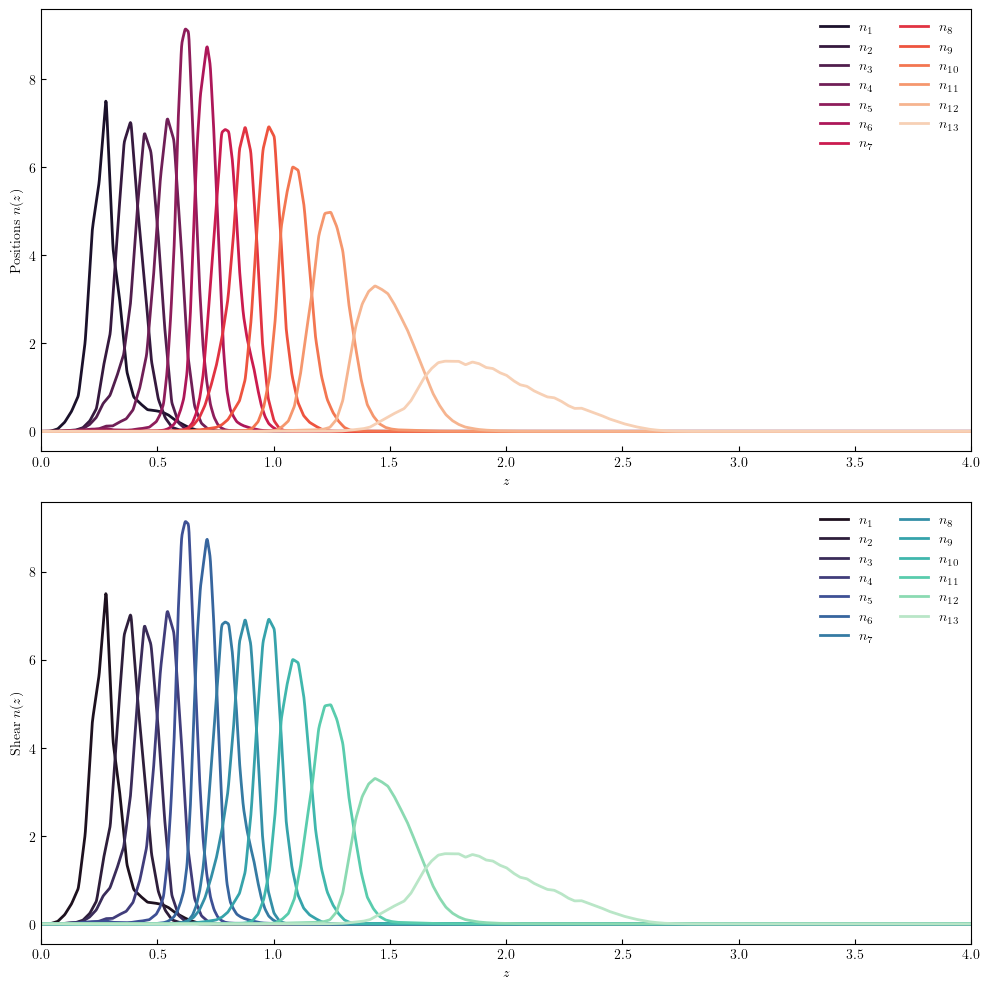

In [4]:
# Plotting of original n(z) distributions #

fig, axs = plt.subplots(2, 1, figsize=(10, 10))

# Customize tick parameters for both axes
for ax in axs.flatten():
    ax.tick_params(axis='both', which='both', direction='in')

# Plot positions n(z)
for i, (key, color) in enumerate(zip(dndz_pos_norm.keys(), sns.color_palette("rocket", len(dndz_pos_norm)))):
    axs[0].plot(z, dndz_pos_norm[key], label=f'$n_{{{i+1}}}$', linewidth=2, color=color)

# Plot shear n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    axs[1].plot(z, dndz_she_norm[key], label=f'$n_{{{j+1}}}$', linewidth=2, color=color)

# Set labels and legends
axs[0].set_xlabel(r'$z$')
axs[0].set_ylabel(r'Positions $n(z)$')
axs[0].set_xlim(0, 4)
axs[0].legend(frameon=False, ncol=2)

axs[1].set_xlabel(r'$z$')
axs[1].set_ylabel(r'Shear $n(z)$')
axs[1].set_xlim(0, 4)
axs[1].legend(frameon=False, ncol=2)

plt.tight_layout()
plt.show()

In [5]:
# Define parameters for GP reconstruction #

z_meds = []   # positions of median redshift for each bin
n_meds = []   # height of n(z) at median redshift for each bin

for key, nz in dndz_she_norm.items():
    # --- CDF & median node ---
    cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
    cdf /= cdf[-1]
    z_med = np.interp(0.5, cdf, z)
    n_med = nz[np.argmin(np.abs(z - z_med))]
    z_meds.append(z_med)
    n_meds.append(n_med)

corr_len = 0.03                                # correlation length for the GP kernel
z_bounds = (0,3)                              # bounds for the redshift
z_pred = np.linspace(0, 3, 400)       # prediction points for GP
alpha = 1e-8                                  # noise level during fitting 
kernel_class = RBF
nu = 1.5                                      # necessary for Matern only, defines smoothness 
const_value = 0.04                            # amplitude of constant kernel
const_bounds = (1e-4, 1.0)                    # bounds for constant kernel amplitude

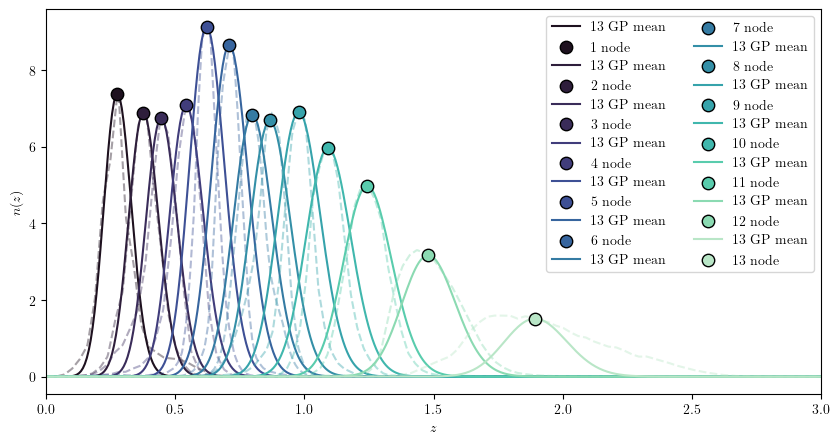

In [6]:
# GP reconstruction and plotting of results #

# Perform GP reconstruction #
priors, predictions = build_gp_nz(n_meds, z_meds, corr_len, z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds)

# Plot GP reconstruction results #
palette = sns.color_palette("mako", 13)
fig, ax = plt.subplots(figsize=(10, 5))

for j, nz in enumerate(n_meds):
    y_pred, y_std = predictions[j]
    X_train, y_train = z_meds[j], n_meds[j]

    ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} GP mean")
    #ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(), (y_pred + y_std).ravel(),
    #                color=palette[j], alpha=0.2)

    ax.plot(z, dndz_she_norm[j+1], '--', color=palette[j], alpha=0.4)
    ax.scatter(X_train, y_train, color=palette[j], edgecolor='black', s=80, zorder=3, label=f"{j+1} node")

ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$n(z)$")
ax.set_xlim(0, 3)
ax.legend(loc="upper right", ncol=2)
plt.show()


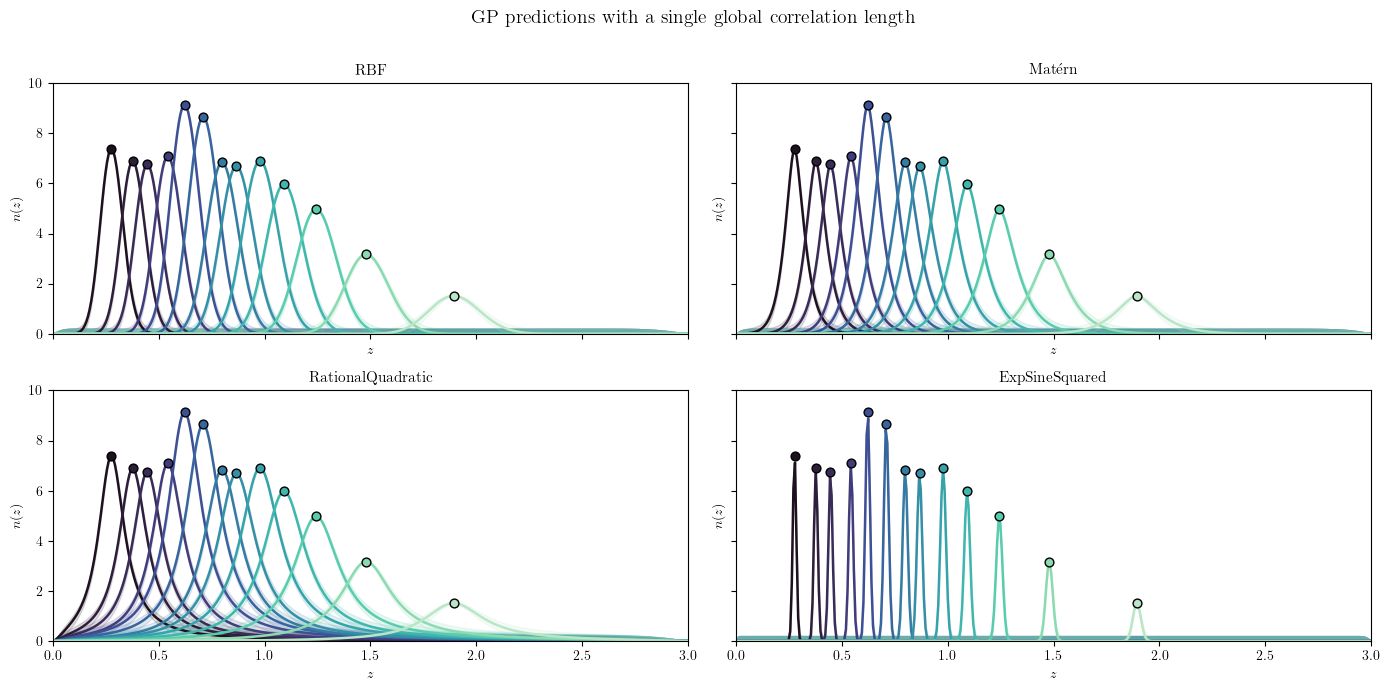

In [7]:
# Results using different kernels #

# Define different kernels #
kernel_dict = {
    "RBF": RBF,
    "Matérn": Matern,
    "RationalQuadratic": RationalQuadratic,
    "ExpSineSquared": ExpSineSquared
}

# Initialize figure for plotting #
n_kernels = len(kernel_dict)
palette = sns.color_palette("mako", len(dndz_she_norm))

fig, axs = plt.subplots(nrows=int(np.ceil(n_kernels/2)), ncols=2,
                        figsize=(14, 3.5 * int(np.ceil(n_kernels/2))),
                        sharex=True, sharey=True)
axs = axs.flatten()

# Compute and plot GP predictions for each kernel #
for ax, (kname, kernel) in zip(axs, kernel_dict.items()):
    
    z_meds = []
    n_meds = []
    for j, (key, nz) in enumerate(dndz_she_norm.items()):
        # --- Compute CDF and median node ---
        cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
        cdf /= cdf[-1]
        z_med = np.interp(0.5, cdf, z)
        n_med = nz[np.argmin(np.abs(z - z_med))]
        z_meds.append(z_med)
        n_meds.append(n_med)

    
    gp_prior, gp_pred = build_gp_nz(n_meds, z_meds, corr_len, z_bounds, z_pred, alpha, kernel, nu, const_value, const_bounds)

    for j, nz in enumerate(n_meds):
        y_pred, y_std = gp_pred[j]
        ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} mean", lw=1.8)
        ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(),
                        (y_pred + y_std).ravel(), color=palette[j], alpha=0.15)
        ax.scatter(z_meds[j], nz, color=palette[j], edgecolor='black', s=40, zorder=3)

        ax.set_title(kname, fontsize=11)
        ax.set_xlim(0, 3)
        ax.set_ylim(0,10)
        ax.set_xlabel(r"$z$")
        ax.set_ylabel(r"$n(z)$")

for ax in axs[len(kernel_dict):]:
    ax.axis("off")

fig.suptitle("GP predictions with a single global correlation length", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


### 2. Guada's work: GP informed by a training node sampled from a prior that is a mean of all possible realiations

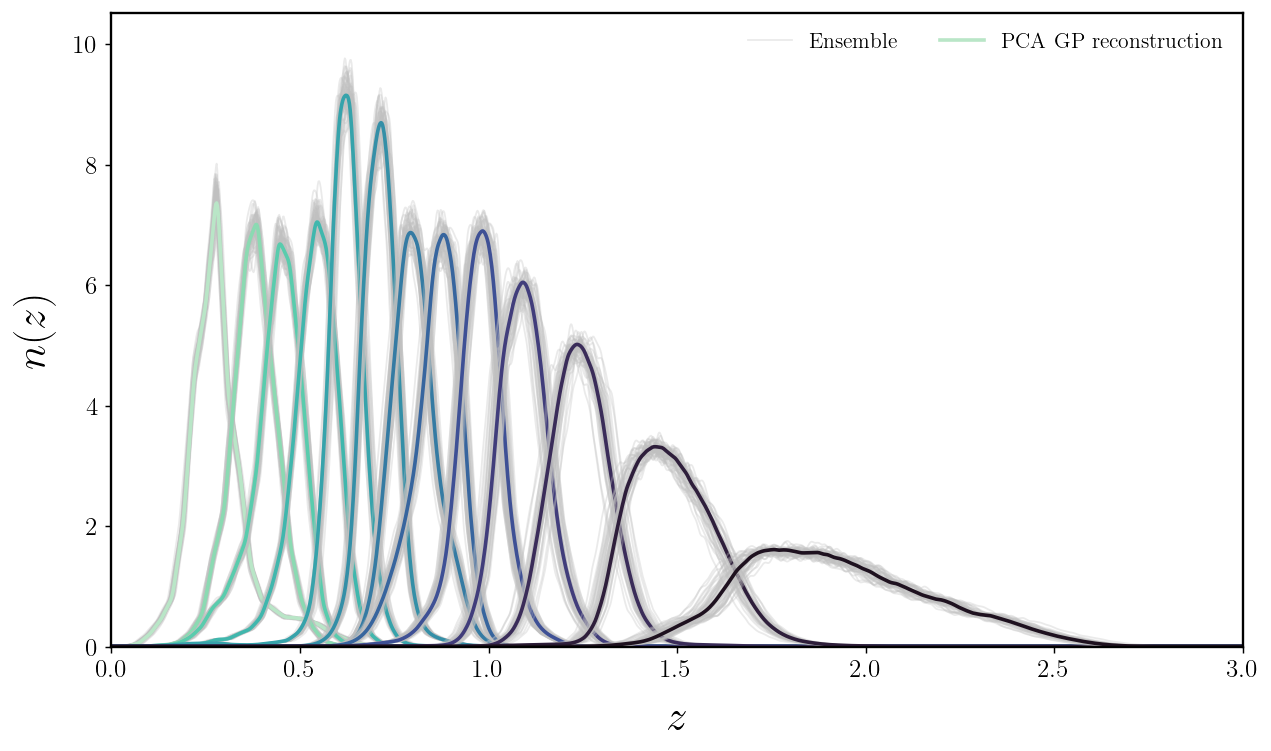

[1.00000000e-03 2.99966667e-03 4.99933333e-03 ... 5.99600067e+00
 5.99800033e+00 6.00000000e+00]


In [13]:
# Define the n(z) ensemble and redshift grid to evaluate on 

import numpy as np
from sklearn.decomposition import PCA


def build_pca_nz_prior(z_grid, nz_ensemble, n_components=5, log_eps=1e-12):
    """
    Build a PCA-based Gaussian prior for n(z) from an ensemble of plausible
    redshift distributions.

    Parameters
    ----------
    z_grid : (N_z,) array
        Redshift grid where all n(z) are evaluated.
    nz_ensemble : (N_ens, N_z) array
        Ensemble of plausible n(z) curves.
    n_components : int, optional
        Number of PCA modes to keep (default: 5).
    log_eps : float, optional
        Small number added inside the log to avoid -inf (default: 1e-12).

    Returns
    -------
    prior : dict
        Dictionary containing everything needed to work with the PCA prior:
        - 'z_grid'        : the redshift grid
        - 'pca'           : trained sklearn.decomposition.PCA object
        - 'coeff_mean'    : (k,) mean of PCA coefficients
        - 'coeff_cov'     : (k,k) covariance of PCA coefficients
        - 'n_components'  : number of retained components
        - 'log_eps'       : epsilon used in the log-transform
    """

    z_grid = np.asarray(z_grid)
    nz_ensemble = np.asarray(nz_ensemble)

    # Normalise each n(z) in the ensemble
    norms = np.trapezoid(nz_ensemble, z_grid, axis=1)
    nz_normed = nz_ensemble / norms[:, None]

    # Log-transform to enforce positivity in reconstruction
    f_ensemble = np.log(nz_normed + log_eps)

    # PCA in function space (each f(z) is a row)
    pca = PCA(n_components=n_components)
    coeffs = pca.fit_transform(f_ensemble)   # shape: (N_ens, k)

    # Empirical Gaussian prior on the PCA coefficients
    coeff_mean = np.mean(coeffs, axis=0)               # (k,)
    coeff_cov = np.cov(coeffs, rowvar=False)           # (k, k)

    prior = {
        "z_grid": z_grid,
        "pca": pca,
        "coeff_mean": coeff_mean,
        "coeff_cov": coeff_cov,
        "n_components": n_components,
        "log_eps": log_eps,
    }

    return prior


def sample_coeffs_from_prior(prior, n_samples=1, random_state=None):
    """
    Draw PCA coefficients from the Gaussian prior defined by the ensemble.

    Parameters
    ----------
    prior : dict
        Output of build_pca_nz_prior.
    n_samples : int, optional
        Number of coefficient vectors to sample (default: 1).
    random_state : int or np.random.Generator, optional
        Seed or RNG for reproducibility.

    Returns
    -------
    coeffs : (n_samples, k) array
        Sampled PCA coefficients.
    """
    mean = prior["coeff_mean"]
    cov = prior["coeff_cov"]

    if isinstance(random_state, np.random.Generator):
        rng = random_state
    else:
        rng = np.random.default_rng(random_state)

    coeffs = rng.multivariate_normal(mean, cov, size=n_samples)
    return coeffs


def reconstruct_nz_from_coeffs(prior, coeffs):
    """
    Reconstruct n(z) from PCA coefficients.

    Parameters
    ----------
    prior : dict
        Output of build_pca_nz_prior.
    coeffs : (k,) or (N, k) array
        PCA coefficients.

    Returns
    -------
    nz : (N_z,) or (N, N_z) array
        Reconstructed, normalised n(z) curves.
    """
    pca = prior["pca"]
    z_grid = prior["z_grid"]
    log_eps = prior["log_eps"]

    coeffs = np.atleast_2d(coeffs)  # (N, k)

    # Inverse PCA: back to f(z) = log n(z)
    f_rec = pca.inverse_transform(coeffs)  # (N, N_z)

    # Undo log-transform and renormalise each curve
    nz = np.exp(f_rec) - log_eps
    nz = np.clip(nz, 0.0, None)

    norms = np.trapezoid(nz, z_grid, axis=1)
    nz /= norms[:, None]

    # If input was 1D coefficients, return 1D n(z)
    if coeffs.shape[0] == 1:
        return nz[0]
    return nz


def best_fit_nz_from_prior(prior):
    """
    Convenience helper: return the 'best-fit' n(z) corresponding to the
    mean PCA coefficients (i.e. the ensemble mean in coefficient space).

    Parameters
    ----------
    prior : dict
        Output of build_pca_nz_prior.

    Returns
    -------
    nz_best : (N_z,) array
        Reconstructed n(z) from mean coefficients.
    """
    coeff_mean = prior["coeff_mean"]
    return reconstruct_nz_from_coeffs(prior, coeff_mean)

import numpy as np
from scipy.ndimage import gaussian_filter1d

def generate_bin1_ensemble(
    N_ens=5,
    z_lo=0.001,
    z_hi=6,
    N_z=3001,
    mean_shift_sigma=0.01,
    width_shift_sigma=0.02,
    shape_noise_sigma=0.07,
    smooth_scale=3,
    nz = dndz_she_norm[1]
):
    """
    Generate an ensemble of n(z) realisations for the FIRST bin only:
        z ∈ [0.001, 0.42]
    using small shifts + smooth perturbations.
    """

    # ---------------------------
    # 1. Grid + base bin n(z)
    # ---------------------------
    z = np.linspace(z_lo, z_hi, N_z)
    nz /= np.trapezoid(nz, z)        # ensure norm within [0, 3] part
    nz_bin = nz.copy()               # for first bin, that's it

    # ---------------------------
    # Build ensemble
    # ---------------------------
    ensemble = []

    z_mean = np.trapezoid(z * nz_bin, z)

    for _ in range(N_ens):

        # Mean shift
        dz = np.random.normal(0, mean_shift_sigma) * z_mean
        z_shift = np.clip(z + dz, z_lo, z_hi)

        # Width/stretch shift
        width = 1 + np.random.normal(0, width_shift_sigma)
        z_stretch = z_mean + width * (z_shift - z_mean)
        z_stretch = np.clip(z_stretch, z_lo, z_hi)

        # Smooth random shape fluctuation
        noise = np.random.normal(0, shape_noise_sigma, N_z)
        noise_smooth = gaussian_filter1d(noise, smooth_scale)
        nz_pert = nz_bin * (1 + noise_smooth)
        nz_pert = np.clip(nz_pert, 1e-12, None)

        # Interpolate to shifted grid
        nz_new = np.interp(z, z_stretch, nz_pert, left=0, right=0)

        # Normalise inside the bin
        nz_new /= np.trapezoid(nz_new, z)

        ensemble.append(nz_new)

    return z, np.array(ensemble)

z_ens_list, nz_ensemble_list = zip(*[
    generate_bin1_ensemble(
        N_ens=50, 
        nz=dndz_she_norm[i], 
        N_z=3001
    )
    for i in range(1, 14)
])

nz_means, nz_samples_list = zip(*[
    (
        best_fit_nz_from_prior( prior := build_pca_nz_prior(
            z_grid := generate_bin1_ensemble(
                N_ens=50,
                nz=dndz_she_norm[i],
                N_z=3001
            )[0],
            nz_ensemble := generate_bin1_ensemble(
                N_ens=50,
                nz=dndz_she_norm[i],
                N_z=3001
            )[1],
            n_components=5
        )),
        reconstruct_nz_from_coeffs(
            prior,
            sample_coeffs_from_prior(prior, n_samples=20, random_state=42)
        )
    )
    for i in range(1, 14)
])

import matplotlib.pyplot as plt
import seaborn as sns

def plot_gp_means_and_ensembles(z_list, nz_ens_list, nz_mean_list, dndz_she_norm):
    """
    Plot ensemble curves and PCA–GP mean curves for bins 1 → 14,
    each in the color corresponding to its key in dndz_she_norm.

    Parameters
    ----------
    z_list : list of arrays
        List of z-grids, one per bin.
    nz_ens_list : list of arrays
        Each element is (N_ens, N_z) ensemble for that bin.
    nz_mean_list : list of arrays
        PCA-GP mean n(z) curves for each bin.
    dndz_she_norm : dict
        Dict whose keys define bin order and color assignment.
    """

    # --- Professional plot style ---
    plt.rcParams.update({
        "font.family": "serif",
        "font.size": 14,
        "axes.labelsize": 16,
        "axes.titlesize": 18,
        "axes.linewidth": 1.3,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 12,
        "figure.dpi": 130
    })

    fig, ax = plt.subplots(figsize=(10, 6))

    # Ordered keys from your dictionary
    keys = list(dndz_she_norm.keys())
    colors = sns.color_palette("mako", len(keys))[::-1]

    # Global y-limit tracking
    global_max = 0

    # --- Loop over bins 1 → N ---
    for j, (key, color) in enumerate(zip(keys, colors)):
        idx = j  # bin index

        z = z_list[idx]
        nz_ens = nz_ens_list[idx]
        nz_mean = nz_mean_list[idx]

        # Plot ensemble realisations (thin, translucent)
        for k, nz_curve in enumerate(nz_ens):
            idx2 = k
            ax.plot(
                z, nz_curve,
                color='silver',
                alpha=0.32,         # very light
                lw=1,
                label="Ensemble" if (idx == 0 and idx2 == 0) else "_nolegend_"
            )

        # Plot PCA mean reconstruction (thick)
        ax.plot(
            z, nz_mean,
            color=color,
            lw=2.,
            label="PCA GP reconstruction" if idx == 0 else "_nolegend_"
        )

        # Track max value
        global_max = max(global_max, nz_mean.max())

    # --- Labels & styling ---
    ax.set_xlabel(r"$z$", labelpad=10, fontsize=24)
    ax.set_ylabel(r"$n(z)$", labelpad=10, fontsize=24)
    ax.set_xlim(0, 3)
    ax.set_ylim(0, 1.15 * global_max)

    ax.legend(frameon=False, edgecolor="black", ncol=2)
    fig.tight_layout()
    plt.savefig("nz_reconstruction_pca_gp.pdf", dpi=300)
    plt.show()

plot_gp_means_and_ensembles(
    z_ens_list,        # list of z arrays (length 14)
    nz_ensemble_list,  # list of ensemble arrays [(50, N_z), ...]
    nz_means,          # list of PCA mean n(z)
    dndz_she_norm      # dict to define ordering + colors
)

print(z_grid)

In [14]:
# Training node sampled from a prior of realizations #

# -----------------------------
# Utilities
# -----------------------------
def x_log1p(z, zmax):
    """Map z to x in [0,1] using log(1+z)."""
    return np.log1p(z) / np.log1p(zmax)

def normalize_nz(z, nz): 
    """
    Normalize the n(z)
    """
    area = np.trapezoid(nz, z)
    area = area if area > 0 else np.finfo(float).tiny
    return nz / area

def kernel_fixed(kernel_class, amp, ell, nu=1.5, amp_bounds=(1e-6, 10.0)):
    """
    Kernel with fixed length-scale ell, fixed (or bounded) amplitude amp.
    We keep optimizer=None, so amp and ell are not learned during GP fitting.
    """
    if kernel_class is Matern:
        return C(amp, amp_bounds) * Matern(length_scale=ell, nu=nu, length_scale_bounds="fixed")
    else:
        return C(amp, amp_bounds) * RBF(length_scale=ell, length_scale_bounds="fixed")


# -----------------------------
# 1) Choose node locations per bin
# -----------------------------
def choose_nodes_from_mean_quantiles(z, nz_mean, quantiles=(0.2, 0.5, 0.8)):
    """
    Choose node locations at given CDF quantiles of the mean n(z).
    """
    nz_mean = normalize_nz(z, np.clip(nz_mean, 0.0, None))
    cdf = np.cumsum((nz_mean[:-1] + nz_mean[1:]) * 0.5 * np.diff(z))
    cdf = np.concatenate([[0.0], cdf])
    cdf = cdf / cdf[-1] if cdf[-1] > 0 else cdf
    z_nodes = np.interp(np.array(quantiles, float), cdf, z)
    return z_nodes


# -----------------------------
# 2) Fit a node-height prior from an ensemble
# -----------------------------
def fit_node_prior_from_ensemble(
    z,
    nz_ensemble,          # (nreal, Nz)
    z_nodes,              # (M,)
    floor_sigma=1e-6,
):
    """
    Returns Gaussian prior params for theta = [n(z_node1),...,n(z_nodeM)]:
        theta ~ N(mu, Sigma)
    computed from the ensemble.
    """
    z = np.asarray(z, float)
    arr = np.asarray(nz_ensemble, float)
    if arr.ndim != 2:
        raise ValueError("nz_ensemble must have shape (nreal, Nz).")
    if arr.shape[1] != z.size:
        raise ValueError("nz_ensemble second dim must match z.")
    z_nodes = np.asarray(z_nodes, float)

    # normalize each realization
    areas = np.trapezoid(arr, z, axis=1)
    areas = np.where(areas > 0, areas, np.finfo(float).tiny)
    arrn = arr / areas[:, None]

    # evaluate node heights by interpolation
    thetas = np.array([np.interp(z_nodes, z, arrn[i]) for i in range(arrn.shape[0])])  # (nreal, M)

    mu = thetas.mean(axis=0)
    Sigma = np.cov(thetas, rowvar=False, ddof=1)
    if thetas.shape[1] == 1:
        Sigma = np.atleast_2d(Sigma)

    # regularize covariance (important if nreal small)
    Sigma = Sigma + (floor_sigma**2) * np.eye(Sigma.shape[0])

    return mu, Sigma # mean and standard deviation of the prior for the node heights 


# -----------------------------
# 3) GP reconstruction FROM NODES (your intended paradigm)
# -----------------------------
def reconstruct_nz_from_nodes_gp(
    z_pred,
    z_nodes,
    theta_nodes,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- set 0 for interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,          # <-- optional like your example
):
    """
    This is the "inferred by the nodes" GP:
      Train on (zmin,0), (z_nodes, theta_nodes), (zmax,0).
      Predict on z_pred.

    IMPORTANT:
    - Do NOT clip/renormalize here if you want the GP mean to pass through nodes.
    - If you need positivity/normalization, do it in the node parameterization
      (e.g., sample log-theta) or use a log-GP model.
    """
    zmin, zmax = z_bounds
    z_pred = np.asarray(z_pred, float)

    # training data (anchors)
    z_train = np.concatenate([[zmin], np.asarray(z_nodes, float), [zmax]])
    y_train = np.concatenate([[0.0], np.asarray(theta_nodes, float), [0.0]])

    X_train = x_log1p(z_train, zmax).reshape(-1, 1)
    X_pred  = x_log1p(z_pred,  zmax).reshape(-1, 1)
    kernel = kernel_fixed(kernel_class, amp=amp, ell=corr_len, nu=nu, amp_bounds=(1e-6, 10.0))

    gp = GaussianProcessRegressor(
        kernel=kernel,
        optimizer=None,
        normalize_y=False,
        alpha=float(alpha),
        copy_X_train=False,
        random_state=0,
    )
    gp.fit(X_train, y_train)

    if return_std:
        y_pred, y_std = gp.predict(X_pred, return_std=True)
        return y_pred, y_std, gp
    else:
        y_pred = gp.predict(X_pred, return_std=False)
        return y_pred


# -----------------------------
# 4) Build per-bin priors + reconstruction wrapper
# -----------------------------
def build_gp_node_priors_per_bin(
    z,
    nz_ensemble_list,          # list len=nbins, each (nreal, Nz)
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8), # choose 3 nodes by default
    floor_sigma=1e-6,
):
    """
    For each bin:
      - choose node locations from mean n(z) quantiles
      - fit Gaussian prior for node heights from ensemble
    """
    priors = []
    for b, arr in enumerate(nz_ensemble_list):
        arr = np.asarray(arr, float)
        if arr.ndim != 2:
            raise ValueError(f"Bin {b}: expected (nreal, Nz), got {arr.shape}")
        if arr.shape[1] != len(z):
            raise ValueError(f"Bin {b}: Nz mismatch")

        # mean curve for node placement
        areas = np.trapezoid(arr, z, axis=1)
        areas = np.where(areas > 0, areas, np.finfo(float).tiny)
        arrn = arr / areas[:, None]
        nz_mean = arrn.mean(axis=0)

        z_nodes = choose_nodes_from_mean_quantiles(z, nz_mean, quantiles=quantiles)
        mu, Sigma = fit_node_prior_from_ensemble(z, arr, z_nodes, floor_sigma=floor_sigma)

        priors.append({
            "z_nodes": z_nodes,
            "mu": mu,
            "Sigma": Sigma,
        })
    return priors


def logprior_nodes_gaussian(theta_nodes, mu, Sigma):
    """
    Log N(theta_nodes | mu, Sigma)
    """
    th = np.asarray(theta_nodes, float).reshape(-1)
    mu = np.asarray(mu, float).reshape(-1)
    Sigma = np.asarray(Sigma, float)

    # stable solve via Cholesky
    L = np.linalg.cholesky(Sigma)
    y = np.linalg.solve(L, th - mu)
    lp = -0.5 * (y @ y) - np.sum(np.log(np.diag(L))) - 0.5 * th.size * np.log(2*np.pi)
    return float(lp)


def reconstruct_all_bins(
    z_pred,
    priors,
    theta_all_bins,            # list of arrays, each shape (M,)
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- use 0.0 if you want interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,
):
    """
    Decode all bins at once: returns list of n_b(z_pred).
    If return_std=True, returns list of (mean,std) per bin.
    """
    out = []
    for b, pb in enumerate(priors):
        if return_std:
            mean, std, _ = reconstruct_nz_from_nodes_gp(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=True,
            )
            out.append((mean, std))
        else:
            nz = reconstruct_nz_from_nodes_gp(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=False,
            )
            out.append(nz)
    return out


# Inputs you already have:
# z_grid: (Nz,) grid
# nz_ensemble_list: list len=13, each (nreal, Nz)

priors = build_gp_node_priors_per_bin(
    z=z_grid,
    nz_ensemble_list=nz_ensemble_list,
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8),  # 3 nodes per bin (tune to 2–5)
)

rng = np.random.default_rng(42)

theta_all_bins = []
for b, pb in enumerate(priors):
    mu = pb["mu"]        # shape (M,)
    Sigma = pb["Sigma"]  # shape (M, M)
    theta_b = rng.multivariate_normal(mu, Sigma)
    theta_all_bins.append(theta_b)

nz_recon = reconstruct_all_bins(
    z_pred=z_grid,
    priors=priors,
    theta_all_bins=theta_all_bins,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,           # <-- crucial for interpolation
)

Text(0.5, 0.98, 'Sampled n(z) ensemble vs GP-node reconstruction')

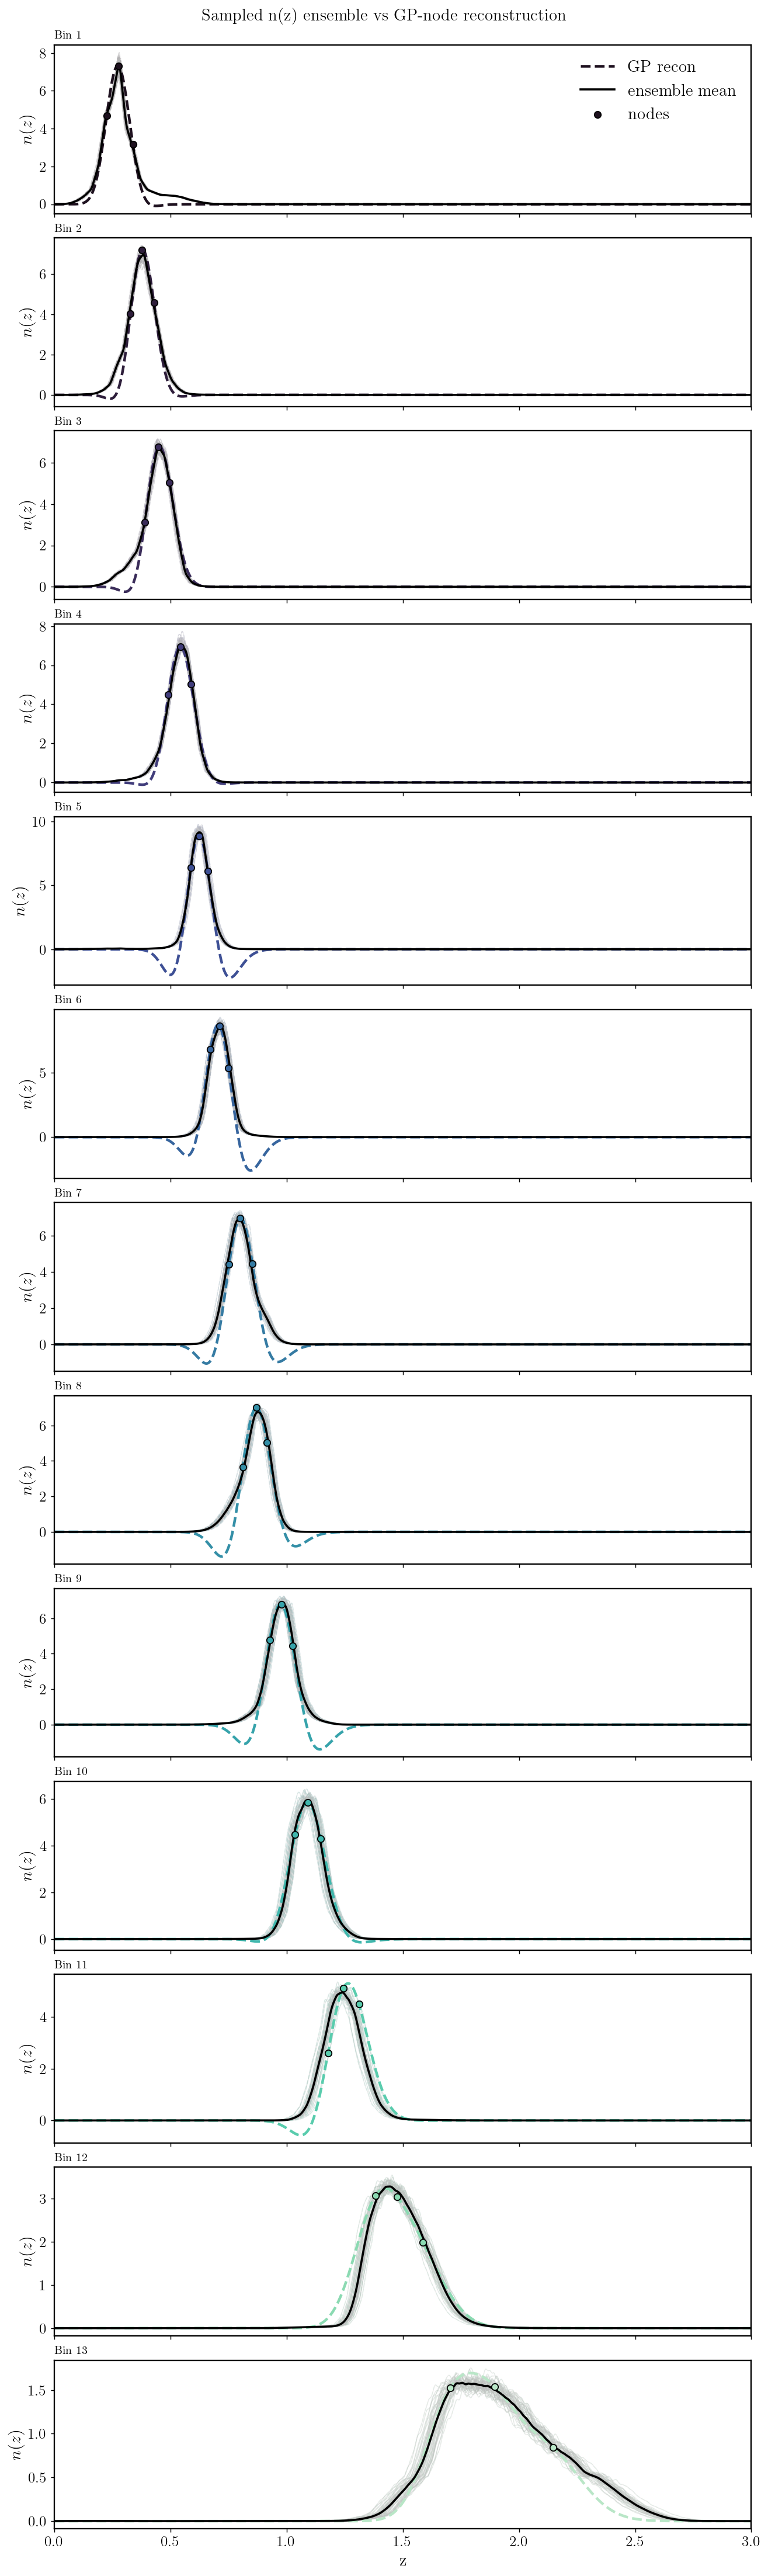

In [15]:
palette = sns.color_palette("mako", len(priors))

n_bins = len(priors)

fig, axes = plt.subplots(
    n_bins, 1,
    figsize=(10, 2.6 * n_bins),
    sharex=True,
    constrained_layout=True
)

for b in range(n_bins):
    ax = axes[b]

    arr = nz_ensemble_list[b]

    # --- Original ensemble (thin dashed)
    for i in range(arr.shape[0]):
        nz_i = arr[i] / np.trapezoid(arr[i], z_grid)
        ax.plot(z_grid, nz_i,
                color=palette[b],
                alpha=0.15, lw=1, ls="--")
        

    # --- Ensemble curves (solid, translucent)
    for i in range(arr.shape[0]):
        ax.plot(z_grid,
                arr[i] / np.trapezoid(arr[i], z_grid),
                color="silver", alpha=0.3, lw=0.8)

    # --- GP reconstruction
    ax.plot(z_grid, nz_recon[b],
            color=palette[b], ls='--', lw=2.5, label="GP recon")

    # --- Ensemble mean
    nz_mean = np.mean(
        arr / np.trapezoid(arr, z_grid, axis=1)[:, None],
        axis=0
    )
    ax.plot(z_grid, nz_mean, color="black", lw=2, label="ensemble mean")

    # --- Node locations
    z_nodes = priors[b]["z_nodes"]
    ax.scatter(z_nodes, theta_all_bins[b],
               s=40, color=palette[b],
               edgecolor="black", zorder=5,
               label="nodes")

    ax.set_ylabel(r"$n(z)$")
    
    ax.set_title(f"Bin {b+1}", loc="left", fontsize=11)
    ax.set_xlim(0, 3)

# Legend only once
axes[0].legend(frameon=False, fontsize=16)

axes[-1].set_xlabel("z")
fig.suptitle("Sampled n(z) ensemble vs GP-node reconstruction", fontsize=16)
#plt.savefig("/home/jipdebuck/plots/new_reconst.png", dpi=600)

### 3. Enforcing positivity by going to log space, while enforcing going to zero at the edges with window function

In [56]:
# Redefining the way we reconstruct n(z) to enforce positivity # 

def window_func(x):
    """
    Window function to ensure positivity.
    The form of this function is up to the user.
    """
    return x*(1-x)

def reconstruct_nz_from_nodes_gp_pos(
    z_pred,
    z_nodes,
    theta_nodes,
    window,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- set 0 for interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,          # <-- optional like your example
):
    """
    This is the "inferred by the nodes" GP:
      Train on (zmin,0), (z_nodes, theta_nodes), (zmax,0).
      Predict on z_pred.

    IMPORTANT:
    - Do NOT clip/renormalize here if you want the GP mean to pass through nodes.
    - If you need positivity/normalization, do it in the node parameterization
      (e.g., sample log-theta) or use a log-GP model.
    """
    zmin, zmax = z_bounds
    z_pred = np.asarray(z_pred, float)

    # training data (anchors)
    z_train = np.asarray(z_nodes, float)
    y_train = np.asarray(theta_nodes, float)

    X_train = x_log1p(z_train, zmax).reshape(-1, 1)
    X_pred  = x_log1p(z_pred, zmax).reshape(-1, 1)
    w_pred = window(X_pred.ravel())

    # applying window function
    w_train = window(X_train.ravel())
    y_train_log = np.log(y_train/w_train)

    kernel = kernel_fixed(kernel_class, amp=amp, ell=corr_len, nu=nu, amp_bounds=(1e-6, 10.0))

    gp = GaussianProcessRegressor(
        kernel=kernel,
        optimizer=None,
        normalize_y=False,
        alpha=float(alpha),
        copy_X_train=False,
        random_state=0,
    )
    gp.fit(X_train, y_train_log)

    if return_std:
        y_pred_log, y_std = gp.predict(X_pred, return_std=True)
        y_pred = w_pred*np.exp(y_pred_log)
        return y_pred, y_std, gp
    else:
        y_pred_log = gp.predict(X_pred, return_std=False)
        y_pred = w_pred*np.exp(y_pred_log)
        return y_pred
    
def reconstruct_all_bins_pos(
    z_pred,
    priors,
    theta_all_bins,            # list of arrays, each shape (M,)
    window,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- use 0.0 if you want interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,
):
    """
    Decode all bins at once: returns list of n_b(z_pred).
    If return_std=True, returns list of (mean,std) per bin.
    """
    out = []
    for b, pb in enumerate(priors):
        if return_std:
            mean, std, _ = reconstruct_nz_from_nodes_gp_pos(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                window=window,
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=True,
            )
            out.append((mean, std))
        else:
            nz = reconstruct_nz_from_nodes_gp_pos(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                window=window,
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=False,
            )
            out.append(nz)
    return out
    
priors = build_gp_node_priors_per_bin(
    z=z_grid,
    nz_ensemble_list=nz_ensemble_list,
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8),  # 3 nodes per bin (tune to 2–5)
)
rng = np.random.default_rng(42)

theta_all_bins = []
for b, pb in enumerate(priors):
    mu = pb["mu"]        # shape (M,)
    Sigma = pb["Sigma"]  # shape (M, M)
    theta_b = rng.multivariate_normal(mu, Sigma)
    theta_all_bins.append(theta_b)

nz_recon = reconstruct_all_bins_pos(
    z_pred=z_grid,
    priors=priors,
    theta_all_bins=theta_all_bins,
    window=window_func,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,           # <-- crucial for interpolation
)


Text(0.5, 0.98, 'Sampled n(z) ensemble vs GP-node reconstruction')

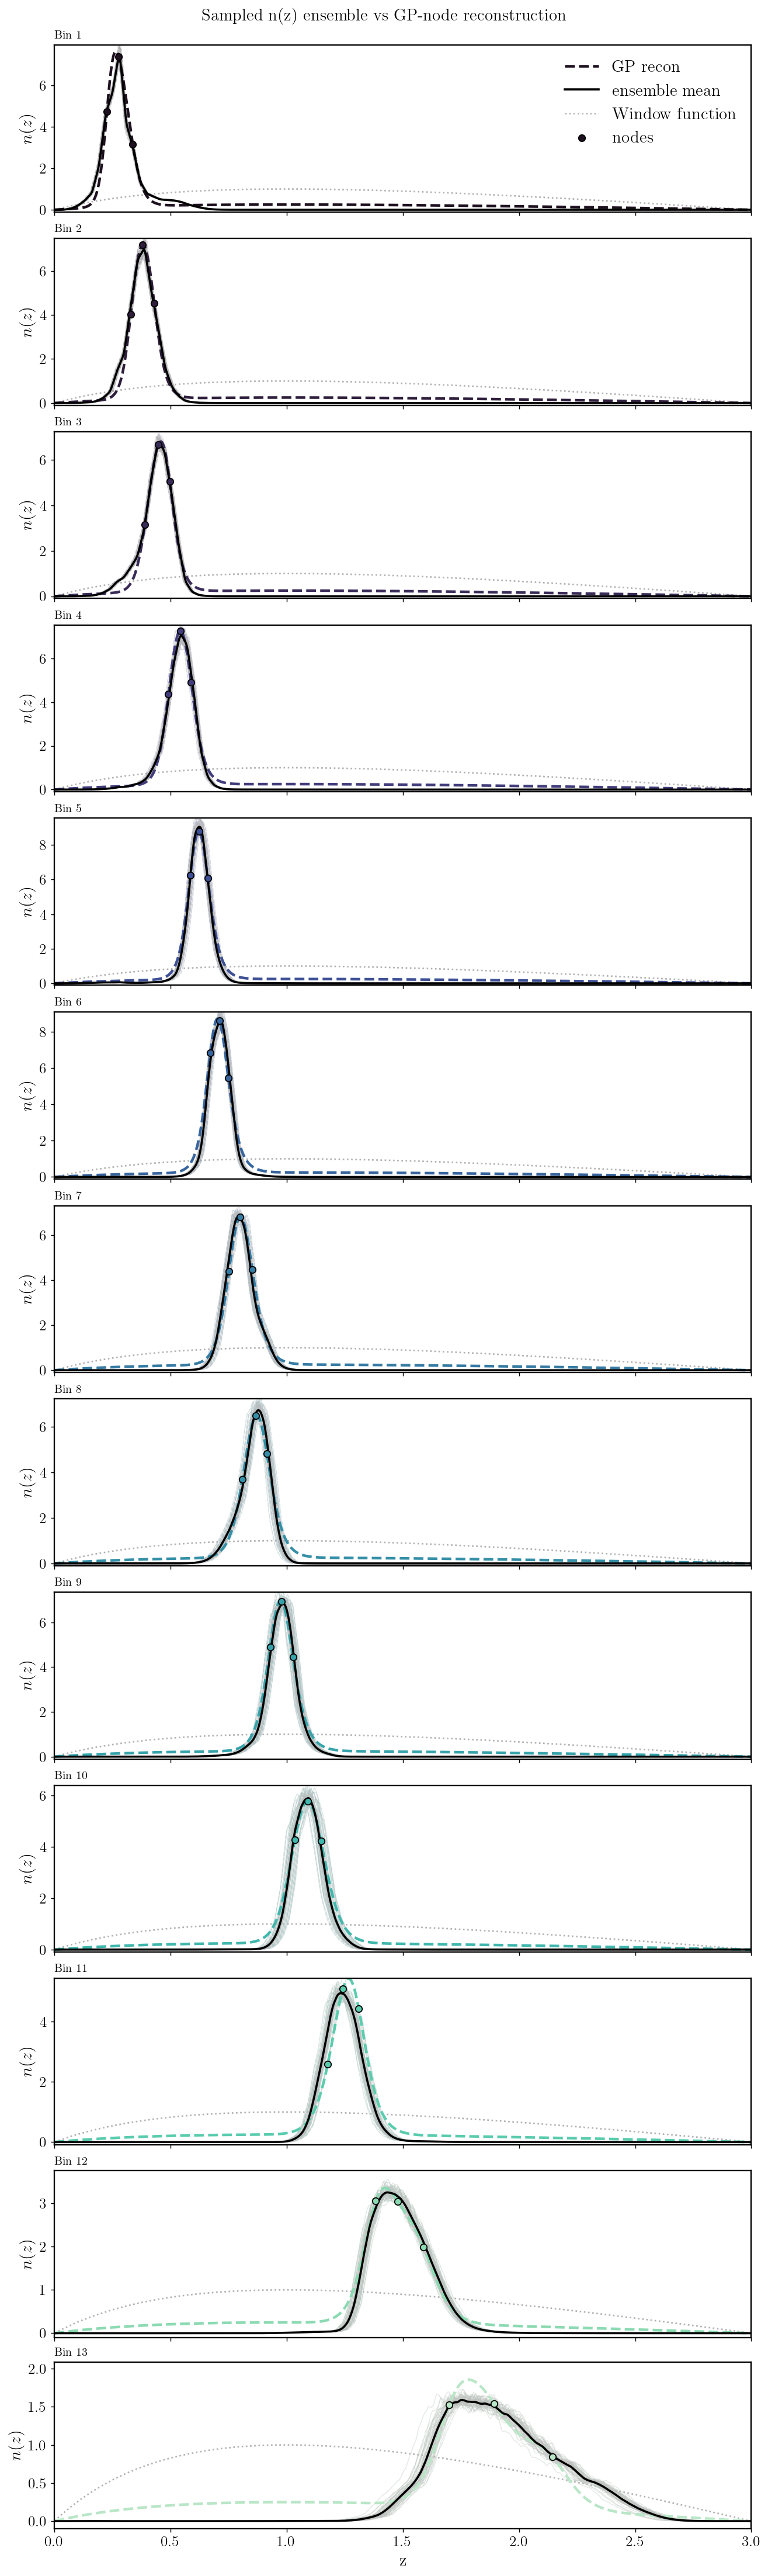

In [54]:
palette = sns.color_palette("mako", len(priors))

n_bins = len(priors)

x_grid = x_log1p(z_grid, 3)
w_grid = window_func(x_grid)
w_grid_norm = w_grid/np.max(w_grid)

fig, axes = plt.subplots(
    n_bins, 1,
    figsize=(10, 2.6 * n_bins),
    sharex=True,
    constrained_layout=True
)

for b in range(n_bins):
    ax = axes[b]

    arr = nz_ensemble_list[b]

    # --- Original ensemble (thin dashed)
    for i in range(arr.shape[0]):
        nz_i = arr[i] / np.trapezoid(arr[i], z_grid)
        ax.plot(z_grid, nz_i,
                color=palette[b],
                alpha=0.15, lw=1, ls="--")
        

    # --- Ensemble curves (solid, translucent)
    for i in range(arr.shape[0]):
        ax.plot(z_grid,
                arr[i] / np.trapezoid(arr[i], z_grid),
                color="silver", alpha=0.3, lw=0.8)

    # --- GP reconstruction
    ax.plot(z_grid, nz_recon[b],
            color=palette[b], ls='--', lw=2.5, label="GP recon")

    # --- Ensemble mean
    nz_mean = np.mean(
        arr / np.trapezoid(arr, z_grid, axis=1)[:, None],
        axis=0
    )
    ax.plot(z_grid, nz_mean, color="black", lw=2, label="ensemble mean")
    ax.plot(z_grid, w_grid_norm, color='black', alpha=0.3, linestyle='dotted', label='Window function', zorder=0)
    # --- Node locations
    z_nodes = priors[b]["z_nodes"]
    ax.scatter(z_nodes, theta_all_bins[b],
               s=40, color=palette[b],
               edgecolor="black", zorder=5,
               label="nodes")

    ax.set_ylabel(r"$n(z)$")
    
    ax.set_title(f"Bin {b+1}", loc="left", fontsize=11)
    ax.set_xlim(0, 3)
    ax.set_ylim(-0.1, np.max(nz_mean)+0.5)
# Legend only once
axes[0].legend(frameon=False, fontsize=16)

axes[-1].set_xlabel("z")
fig.suptitle("Sampled n(z) ensemble vs GP-node reconstruction", fontsize=16)

### 4. Enforcing positivity by going to log-space, while enforcing going to zero at edges with training nodes 

In [60]:
# Redefining the way we reconstruct n(z) to enforce positivity # 

def reconstruct_nz_from_nodes_gp_log(
    z_pred,
    z_nodes,
    theta_nodes,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- set 0 for interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,          # <-- optional like your example
):
    """
    This is the "inferred by the nodes" GP:
      Train on (zmin,0), (z_nodes, theta_nodes), (zmax,0).
      Predict on z_pred.

    IMPORTANT:
    - Do NOT clip/renormalize here if you want the GP mean to pass through nodes.
    - If you need positivity/normalization, do it in the node parameterization
      (e.g., sample log-theta) or use a log-GP model.
    """
    zmin, zmax = z_bounds
    z_pred = np.asarray(z_pred, float)

    # training data (anchors)
    z_train = np.concatenate([[zmin], np.asarray(z_nodes, float), [zmax]])
    y_train = np.concatenate([[1e-7], np.asarray(theta_nodes, float), [1e-7]])

    X_train = x_log1p(z_train, zmax).reshape(-1, 1)
    X_pred  = x_log1p(z_pred, zmax).reshape(-1, 1)

    y_train_log = np.log(y_train)

    kernel = kernel_fixed(kernel_class, amp=amp, ell=corr_len, nu=nu, amp_bounds=(1e-6, 10.0))

    gp = GaussianProcessRegressor(
        kernel=kernel,
        optimizer=None,
        normalize_y=False,
        alpha=float(alpha),
        copy_X_train=False,
        random_state=0,
    )
    gp.fit(X_train, y_train_log)

    if return_std:
        y_pred_log, y_std = gp.predict(X_pred, return_std=True)
        y_pred = np.exp(y_pred_log)
        return y_pred, y_std, gp
    else:
        y_pred_log = gp.predict(X_pred, return_std=False)
        y_pred = np.exp(y_pred_log)
        return y_pred
    
def reconstruct_all_bins_log(
    z_pred,
    priors,
    theta_all_bins,            # list of arrays, each shape (M,)
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- use 0.0 if you want interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,
):
    """
    Decode all bins at once: returns list of n_b(z_pred).
    If return_std=True, returns list of (mean,std) per bin.
    """
    out = []
    for b, pb in enumerate(priors):
        if return_std:
            mean, std, _ = reconstruct_nz_from_nodes_gp_log(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=True,
            )
            out.append((mean, std))
        else:
            nz = reconstruct_nz_from_nodes_gp_log(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=False,
            )
            out.append(nz)
    return out
    
priors = build_gp_node_priors_per_bin(
    z=z_grid,
    nz_ensemble_list=nz_ensemble_list,
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8),  # 3 nodes per bin (tune to 2–5)
)
rng = np.random.default_rng(42)

theta_all_bins = []
for b, pb in enumerate(priors):
    mu = pb["mu"]        # shape (M,)
    Sigma = pb["Sigma"]  # shape (M, M)
    theta_b = rng.multivariate_normal(mu, Sigma)
    theta_all_bins.append(theta_b)

nz_recon = reconstruct_all_bins_log(
    z_pred=z_grid,
    priors=priors,
    theta_all_bins=theta_all_bins,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,           # <-- crucial for interpolation
)


Text(0.5, 0.98, 'Sampled n(z) ensemble vs GP-node reconstruction')

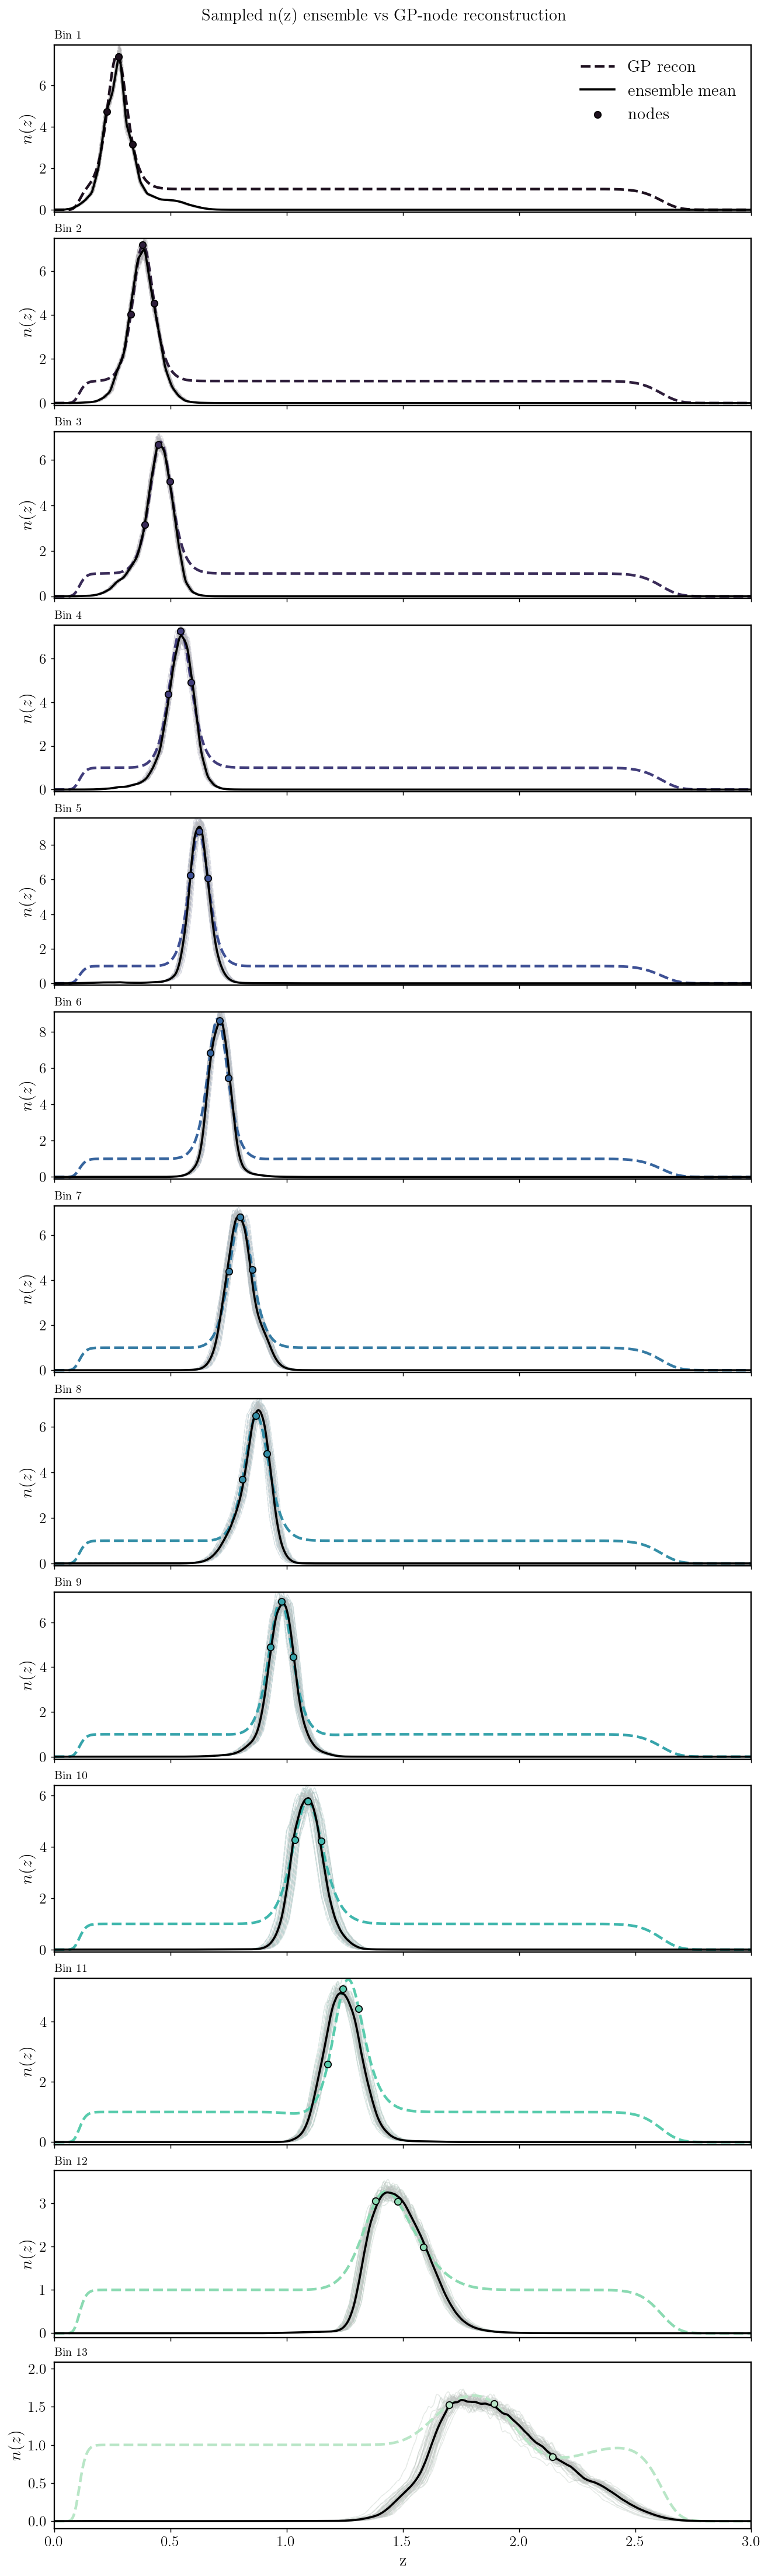

In [61]:
palette = sns.color_palette("mako", len(priors))

n_bins = len(priors)

fig, axes = plt.subplots(
    n_bins, 1,
    figsize=(10, 2.6 * n_bins),
    sharex=True,
    constrained_layout=True
)

for b in range(n_bins):
    ax = axes[b]

    arr = nz_ensemble_list[b]

    # --- Original ensemble (thin dashed)
    for i in range(arr.shape[0]):
        nz_i = arr[i] / np.trapezoid(arr[i], z_grid)
        ax.plot(z_grid, nz_i,
                color=palette[b],
                alpha=0.15, lw=1, ls="--")
        

    # --- Ensemble curves (solid, translucent)
    for i in range(arr.shape[0]):
        ax.plot(z_grid,
                arr[i] / np.trapezoid(arr[i], z_grid),
                color="silver", alpha=0.3, lw=0.8)

    # --- GP reconstruction
    ax.plot(z_grid, nz_recon[b],
            color=palette[b], ls='--', lw=2.5, label="GP recon")

    # --- Ensemble mean
    nz_mean = np.mean(
        arr / np.trapezoid(arr, z_grid, axis=1)[:, None],
        axis=0
    )
    ax.plot(z_grid, nz_mean, color="black", lw=2, label="ensemble mean")
    
    # --- Node locations
    z_nodes = priors[b]["z_nodes"]
    ax.scatter(z_nodes, theta_all_bins[b],
               s=40, color=palette[b],
               edgecolor="black", zorder=5,
               label="nodes")

    ax.set_ylabel(r"$n(z)$")
    
    ax.set_title(f"Bin {b+1}", loc="left", fontsize=11)
    ax.set_xlim(0, 3)
    ax.set_ylim(-0.1, np.max(nz_mean)+0.5)
# Legend only once
axes[0].legend(frameon=False, fontsize=16)

axes[-1].set_xlabel("z")
fig.suptitle("Sampled n(z) ensemble vs GP-node reconstruction", fontsize=16)

### 5. Enforcing positivity by going to squared space, while ensuring going to zero with training nodes at edges

In [18]:
def reconstruct_nz_from_nodes_gp_square(
    z_pred,
    z_nodes,
    theta_nodes,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- set 0 for interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,          # <-- optional like your example
):
    """
    This is the "inferred by the nodes" GP:
      Train on (zmin,0), (z_nodes, theta_nodes), (zmax,0).
      Predict on z_pred.

    IMPORTANT:
    - Do NOT clip/renormalize here if you want the GP mean to pass through nodes.
    - If you need positivity/normalization, do it in the node parameterization
      (e.g., sample log-theta) or use a log-GP model.
    """
    zmin, zmax = z_bounds
    z_pred = np.asarray(z_pred, float)

    # training data (anchors)
    z_train = np.concatenate([[zmin], np.asarray(z_nodes, float), [zmax]])
    y_train_squareroot = np.concatenate([[0], np.asarray(np.sqrt(theta_nodes), float), [0]])

    X_train = x_log1p(z_train, zmax).reshape(-1, 1)
    X_pred  = x_log1p(z_pred, zmax).reshape(-1, 1)

    kernel = kernel_fixed(kernel_class, amp=amp, ell=corr_len, nu=nu, amp_bounds=(1e-6, 10.0))

    gp = GaussianProcessRegressor(
        kernel=kernel,
        optimizer=None,
        normalize_y=False,
        alpha=float(alpha),
        copy_X_train=False,
        random_state=0,
    )
    gp.fit(X_train, y_train_squareroot)

    if return_std:
        y_pred_squareroot, y_std = gp.predict(X_pred, return_std=True)
        y_pred = y_pred_squareroot**2
        return y_pred, y_std, gp
    else:
        y_pred_squareroot = gp.predict(X_pred, return_std=False)
        y_pred = y_pred_squareroot**2
        return y_pred

def reconstruct_all_bins_square(
    z_pred,
    priors,
    theta_all_bins,            # list of arrays, each shape (M,)
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- use 0.0 if you want interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,
):
    """
    Decode all bins at once: returns list of n_b(z_pred).
    If return_std=True, returns list of (mean,std) per bin.
    """
    out = []
    for b, pb in enumerate(priors):
        if return_std:
            mean, std, _ = reconstruct_nz_from_nodes_gp_square(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=True,
            )
            out.append((mean, std))
        else:
            nz = reconstruct_nz_from_nodes_gp_square(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=False,
            )
            out.append(nz)
    return out
    
priors = build_gp_node_priors_per_bin(
    z=z_grid,
    nz_ensemble_list=nz_ensemble_list,
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8),  # 3 nodes per bin (tune to 2–5)
)
rng = np.random.default_rng(42)

theta_all_bins = []
for b, pb in enumerate(priors):
    mu = pb["mu"]        # shape (M,)
    Sigma = pb["Sigma"]  # shape (M, M)
    theta_b = rng.multivariate_normal(mu, Sigma)
    theta_all_bins.append(theta_b)

nz_recon = reconstruct_all_bins_square(
    z_pred=z_grid,
    priors=priors,
    theta_all_bins=theta_all_bins,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,           # <-- crucial for interpolation
)


Text(0.5, 0.98, 'Sampled n(z) ensemble vs GP-node reconstruction')

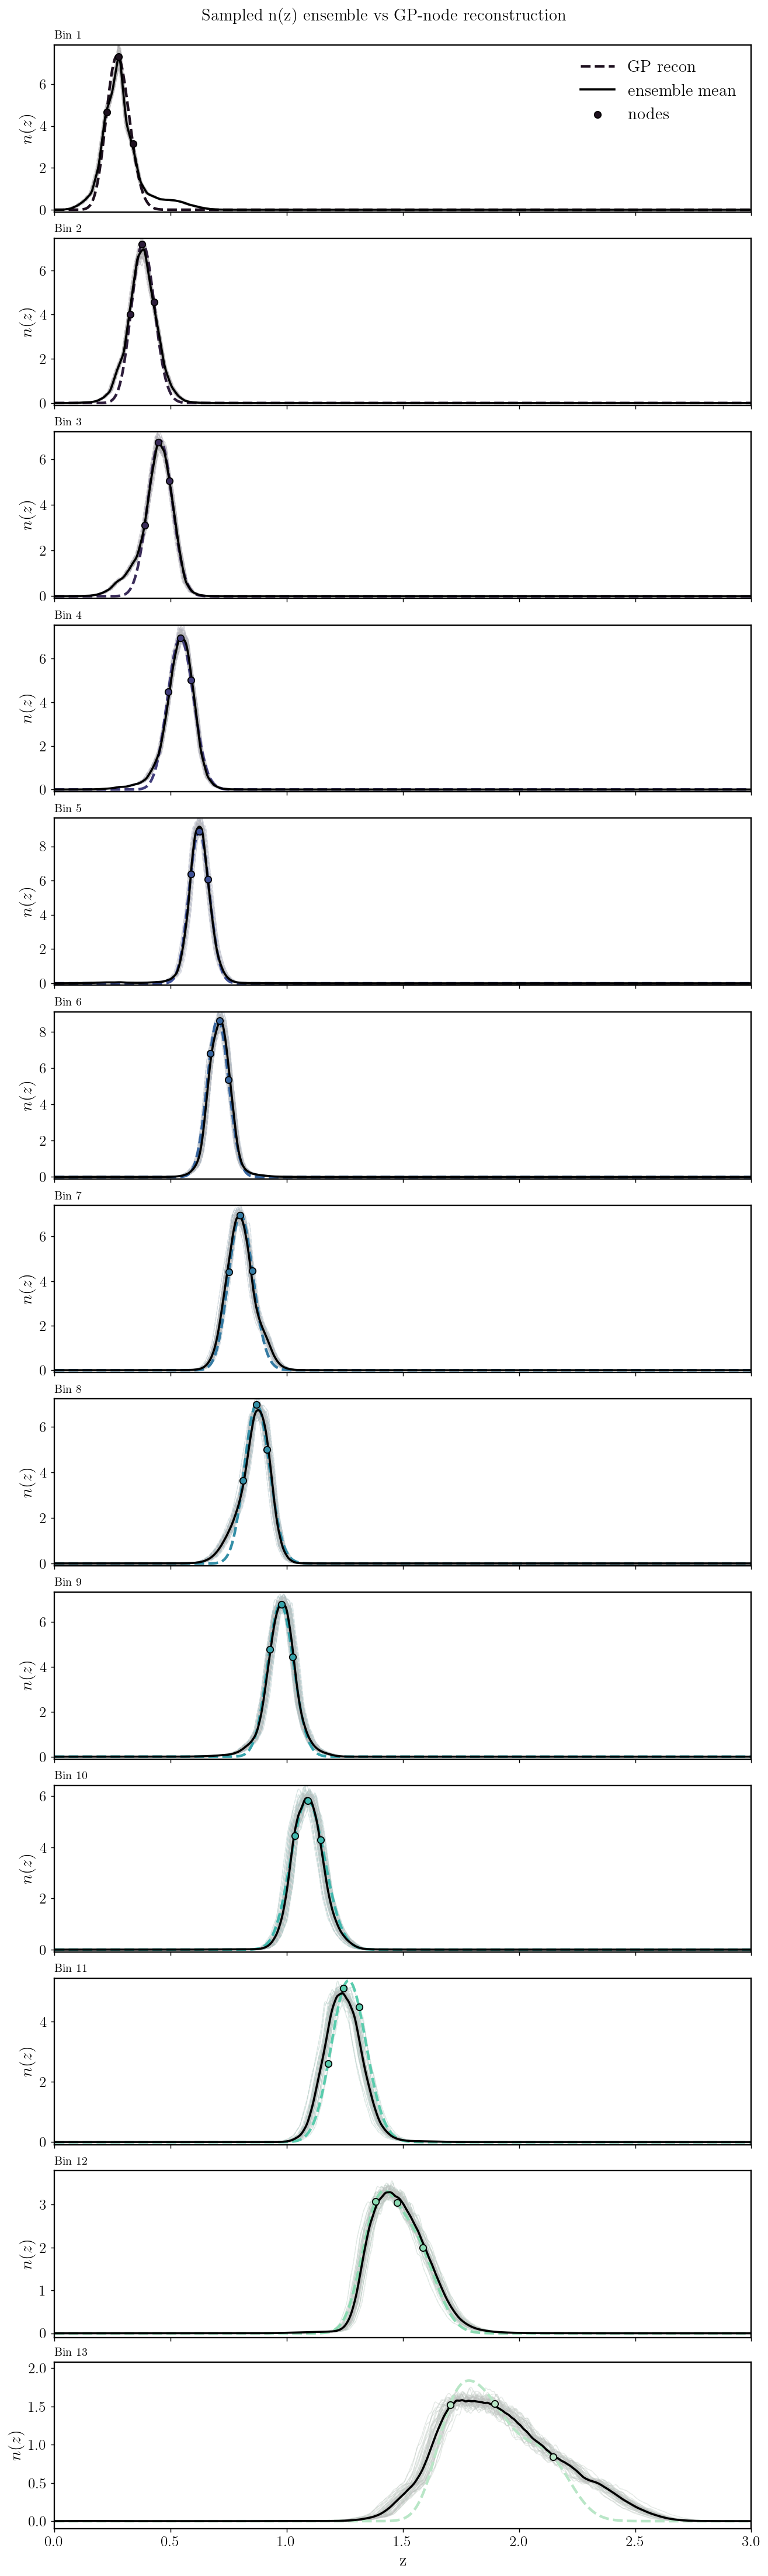

In [19]:
palette = sns.color_palette("mako", len(priors))

n_bins = len(priors)

fig, axes = plt.subplots(
    n_bins, 1,
    figsize=(10, 2.6 * n_bins),
    sharex=True,
    constrained_layout=True
)

for b in range(n_bins):
    ax = axes[b]

    arr = nz_ensemble_list[b]

    # --- Original ensemble (thin dashed)
    for i in range(arr.shape[0]):
        nz_i = arr[i] / np.trapezoid(arr[i], z_grid)
        ax.plot(z_grid, nz_i,
                color=palette[b],
                alpha=0.15, lw=1, ls="--")
        

    # --- Ensemble curves (solid, translucent)
    for i in range(arr.shape[0]):
        ax.plot(z_grid,
                arr[i] / np.trapezoid(arr[i], z_grid),
                color="silver", alpha=0.3, lw=0.8)

    # --- GP reconstruction
    ax.plot(z_grid, nz_recon[b],
            color=palette[b], ls='--', lw=2.5, label="GP recon")

    # --- Ensemble mean
    nz_mean = np.mean(
        arr / np.trapezoid(arr, z_grid, axis=1)[:, None],
        axis=0
    )
    ax.plot(z_grid, nz_mean, color="black", lw=2, label="ensemble mean")
    
    # --- Node locations
    z_nodes = priors[b]["z_nodes"]
    ax.scatter(z_nodes, theta_all_bins[b],
               s=40, color=palette[b],
               edgecolor="black", zorder=5,
               label="nodes")

    ax.set_ylabel(r"$n(z)$")
    
    ax.set_title(f"Bin {b+1}", loc="left", fontsize=11)
    ax.set_xlim(0, 3)
    ax.set_ylim(-0.1, np.max(nz_mean)+0.5)
# Legend only once
axes[0].legend(frameon=False, fontsize=16)

axes[-1].set_xlabel("z")
fig.suptitle("Sampled n(z) ensemble vs GP-node reconstruction", fontsize=16)

### 6. Implementing the prior for DR1, i.e. 13 --> 6 bins

In [20]:
# Load in the DR1 n(z) 
z, nz = el.phz.redshift_distributions('/home/jipdebuck/nz_example.fits')

# Normalize both dndz_pos and dndz_she
dndz_pos_norm = normalize_dndz(nz, z)
dndz_she_norm = normalize_dndz(nz, z)

# Resampling the normalized dndz with 100 values
my_dndz_pos_norm = resample_dndz(dndz_pos_norm, z, zs)
my_dndz_she_norm = resample_dndz(dndz_she_norm, z, zs)


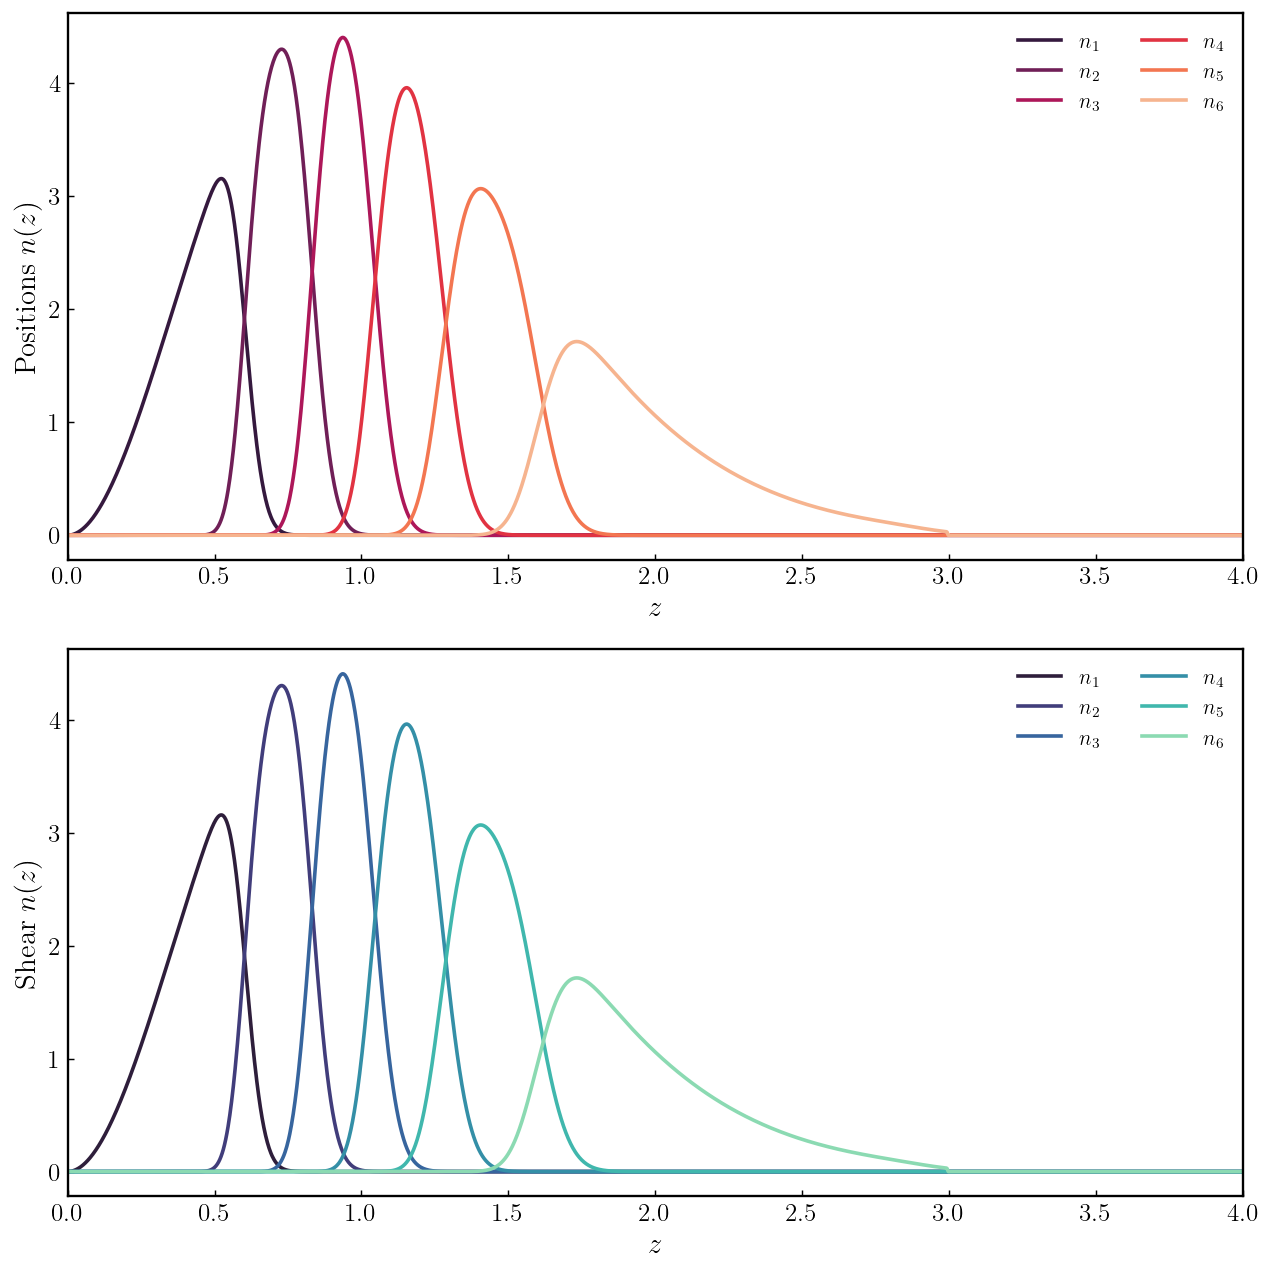

In [21]:
# Plotting of original n(z) distributions #

fig, axs = plt.subplots(2, 1, figsize=(10, 10))

# Customize tick parameters for both axes
for ax in axs.flatten():
    ax.tick_params(axis='both', which='both', direction='in')

# Plot positions n(z)
for i, (key, color) in enumerate(zip(dndz_pos_norm.keys(), sns.color_palette("rocket", len(dndz_pos_norm)))):
    axs[0].plot(z, dndz_pos_norm[key], label=f'$n_{{{i+1}}}$', linewidth=2, color=color)

# Plot shear n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    axs[1].plot(z, dndz_she_norm[key], label=f'$n_{{{j+1}}}$', linewidth=2, color=color)

# Set labels and legends
axs[0].set_xlabel(r'$z$')
axs[0].set_ylabel(r'Positions $n(z)$')
axs[0].set_xlim(0, 4)
axs[0].legend(frameon=False, ncol=2)

axs[1].set_xlabel(r'$z$')
axs[1].set_ylabel(r'Shear $n(z)$')
axs[1].set_xlim(0, 4)
axs[1].legend(frameon=False, ncol=2)

plt.tight_layout()
plt.show()

In [22]:
# Define parameters for GP reconstruction #

z_meds = []   # positions of median redshift for each bin
n_meds = []   # height of n(z) at median redshift for each bin

for key, nz in dndz_she_norm.items():
    # --- CDF & median node ---
    cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
    cdf /= cdf[-1]
    z_med = np.interp(0.5, cdf, z)
    n_med = nz[np.argmin(np.abs(z - z_med))]
    z_meds.append(z_med)
    n_meds.append(n_med)

corr_len = 0.03                                # correlation length for the GP kernel
z_bounds = (0,3)                              # bounds for the redshift
z_pred = np.linspace(0, 3, 400)       # prediction points for GP
alpha = 1e-8                                  # noise level during fitting 
kernel_class = RBF
nu = 1.5                                      # necessary for Matern only, defines smoothness 
const_value = 0.04                            # amplitude of constant kernel
const_bounds = (1e-4, 1.0)                    # bounds for constant kernel amplitude

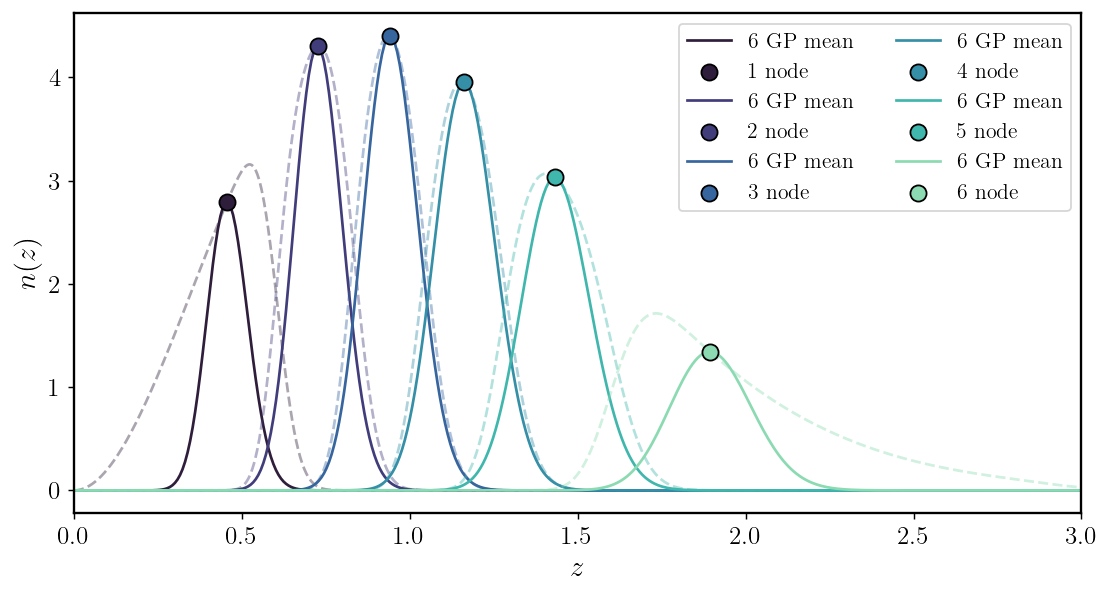

In [23]:
# GP reconstruction and plotting of results #

# Perform GP reconstruction #
priors, predictions = build_gp_nz(n_meds, z_meds, corr_len, z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds)

# Plot GP reconstruction results #
palette = sns.color_palette("mako", 6)
fig, ax = plt.subplots(figsize=(10, 5))

for j, nz in enumerate(n_meds):
    y_pred, y_std = predictions[j]
    X_train, y_train = z_meds[j], n_meds[j]

    ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} GP mean")
    #ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(), (y_pred + y_std).ravel(),
    #                color=palette[j], alpha=0.2)

    ax.plot(z, dndz_she_norm[j+1], '--', color=palette[j], alpha=0.4)
    ax.scatter(X_train, y_train, color=palette[j], edgecolor='black', s=80, zorder=3, label=f"{j+1} node")

ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$n(z)$")
ax.set_xlim(0, 3)
ax.legend(loc="upper right", ncol=2)
plt.show()

In [ ]:
# Creating a list of plausible n(z) realizations

z_ens_list, nz_ensemble_list = zip(*[
    generate_bin1_ensemble(
        N_ens=50, 
        nz=dndz_she_norm[i], 
        N_z=3001
    )
    for i in range(1, 7)
])

In [27]:
# Building the prior for the heights of the training nodes from the n(z) ensemble

priors = build_gp_node_priors_per_bin(
    z=z_grid,
    nz_ensemble_list=nz_ensemble_list,
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8),  # 3 nodes per bin (tune to 2–5)
)

rng = np.random.default_rng(42)

theta_all_bins = []
for b, pb in enumerate(priors):
    mu = pb["mu"]        # shape (M,)
    Sigma = pb["Sigma"]  # shape (M, M)
    theta_b = rng.multivariate_normal(mu, Sigma)
    theta_all_bins.append(theta_b)

nz_recon = reconstruct_all_bins(
    z_pred=z_grid,
    priors=priors,
    theta_all_bins=theta_all_bins,
    z_bounds=(0.0, 3.0),
    corr_len=0.035,
    amp=0.04,
    alpha=0.0,           # <-- crucial for interpolation
)

Text(0.5, 0.98, 'Sampled n(z) ensemble vs GP-node reconstruction')

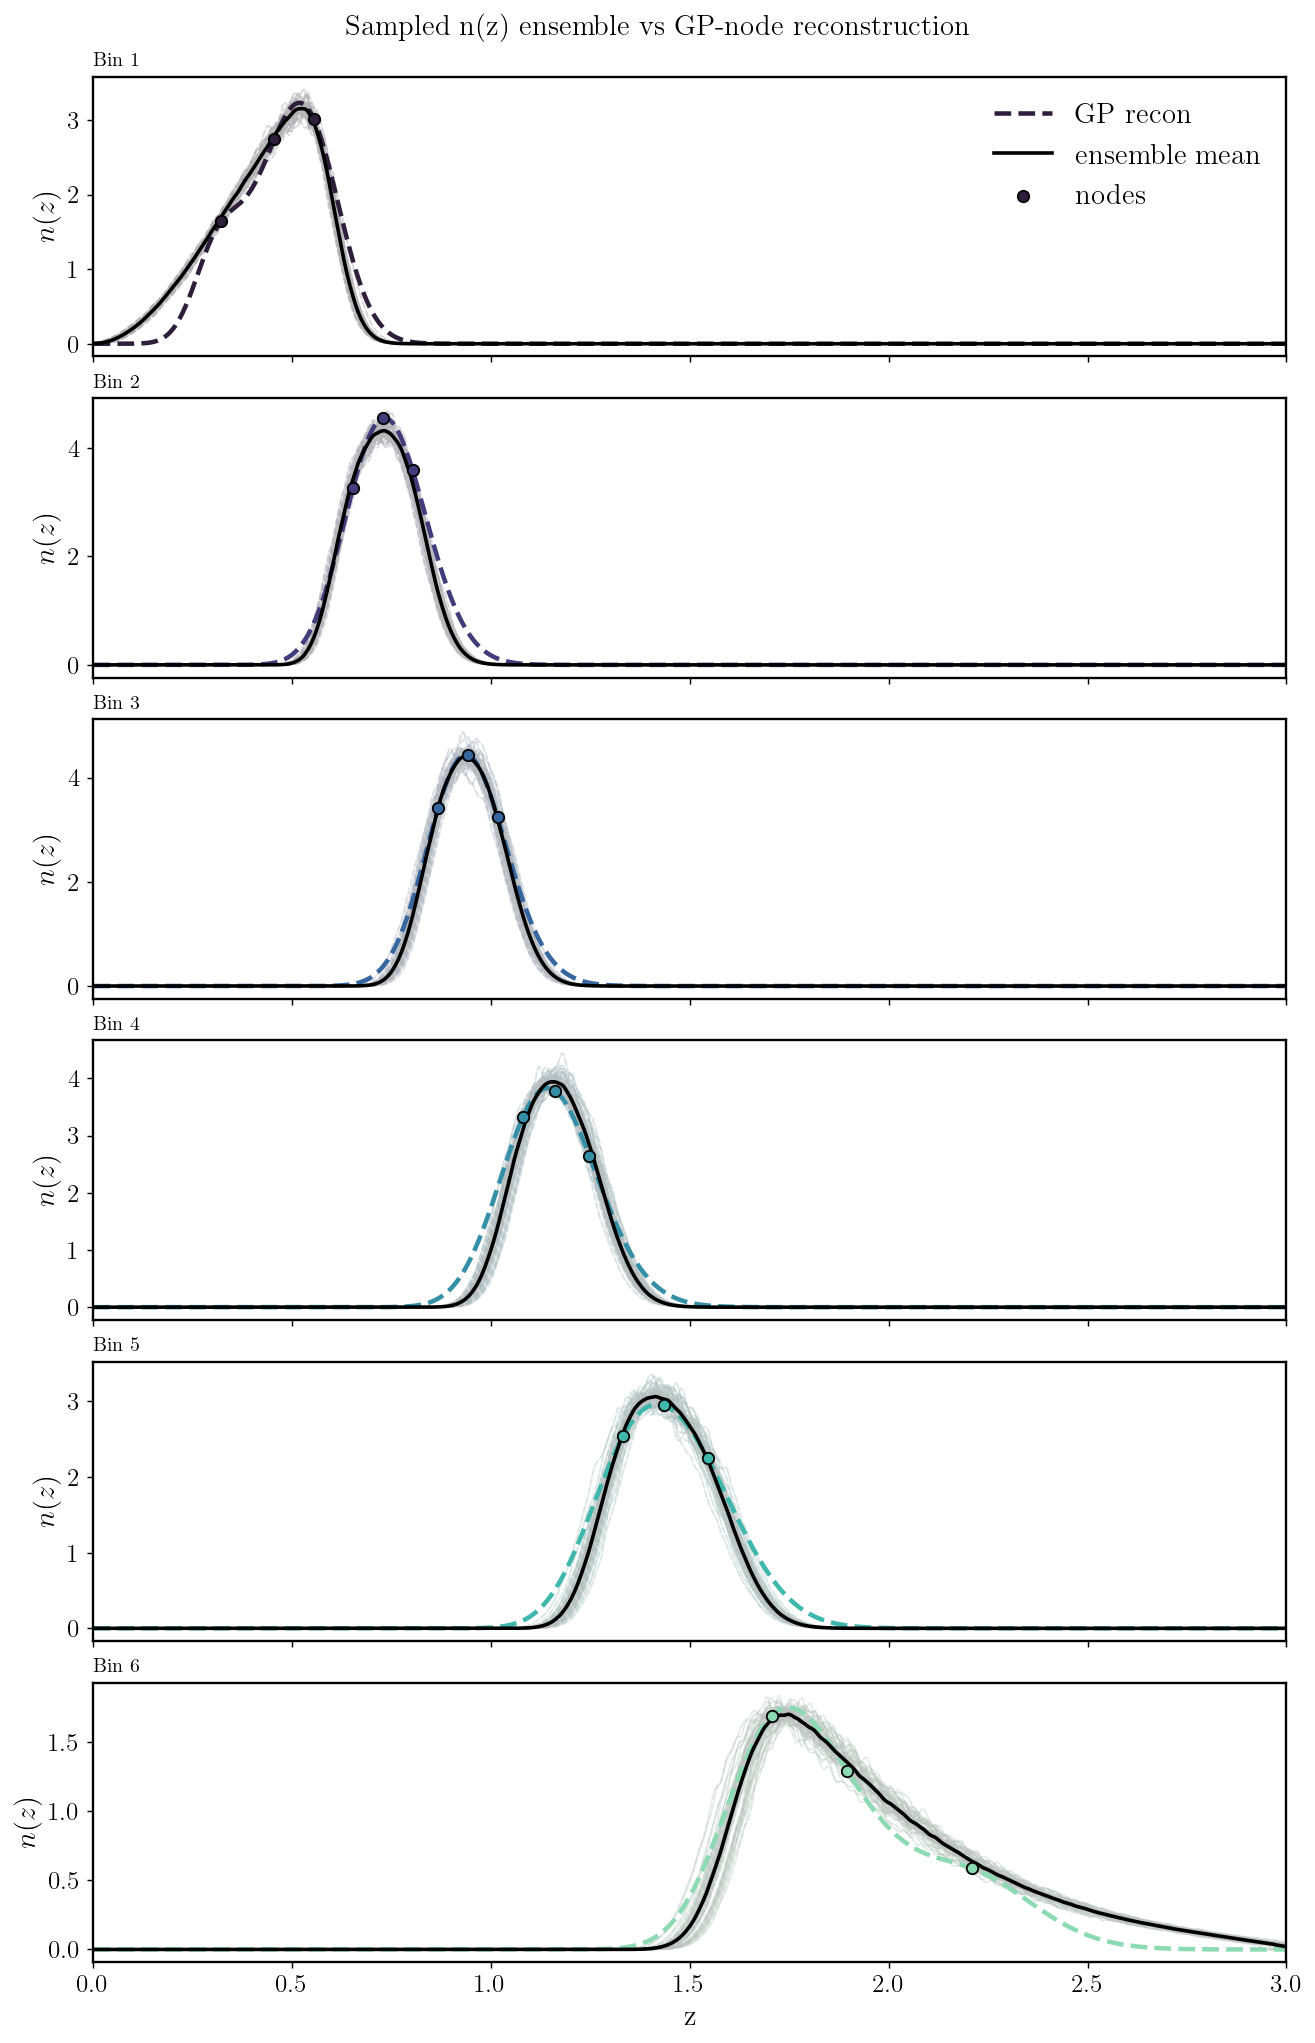

In [28]:
# Plotting the reconstructions per bin

palette = sns.color_palette("mako", len(priors))

n_bins = len(priors)

fig, axes = plt.subplots(
    n_bins, 1,
    figsize=(10, 2.6 * n_bins),
    sharex=True,
    constrained_layout=True
)

for b in range(n_bins):
    ax = axes[b]

    arr = nz_ensemble_list[b]

    # --- Original ensemble (thin dashed)
    for i in range(arr.shape[0]):
        nz_i = arr[i] / np.trapezoid(arr[i], z_grid)
        ax.plot(z_grid, nz_i,
                color=palette[b],
                alpha=0.15, lw=1, ls="--")
        

    # --- Ensemble curves (solid, translucent)
    for i in range(arr.shape[0]):
        ax.plot(z_grid,
                arr[i] / np.trapezoid(arr[i], z_grid),
                color="silver", alpha=0.3, lw=0.8)

    # --- GP reconstruction
    ax.plot(z_grid, nz_recon[b],
            color=palette[b], ls='--', lw=2.5, label="GP recon")

    # --- Ensemble mean
    nz_mean = np.mean(
        arr / np.trapezoid(arr, z_grid, axis=1)[:, None],
        axis=0
    )
    ax.plot(z_grid, nz_mean, color="black", lw=2, label="ensemble mean")

    # --- Node locations
    z_nodes = priors[b]["z_nodes"]
    ax.scatter(z_nodes, theta_all_bins[b],
               s=40, color=palette[b],
               edgecolor="black", zorder=5,
               label="nodes")

    ax.set_ylabel(r"$n(z)$")
    
    ax.set_title(f"Bin {b+1}", loc="left", fontsize=11)
    ax.set_xlim(0, 3)

# Legend only once
axes[0].legend(frameon=False, fontsize=16)

axes[-1].set_xlabel("z")
fig.suptitle("Sampled n(z) ensemble vs GP-node reconstruction", fontsize=16)
#plt.savefig("/home/jipdebuck/plots/new_reconst.png", dpi=600)

### 7. Applying the prior to a cosmological chain for DR1 

In [ ]:
# Code to run on Leonardo

# General imports

import os
os.environ["OMP_NUM_THREADS"] = "1"
#os.environ["OPENBLAS_NUM_THREADS"] = "1"
#os.environ["MKL_NUM_THREADS"] = "1"
#os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
#os.environ["NUMEXPR_NUM_THREADS"] = "1"


import numpy as np
from scipy.interpolate import interp1d
from scipy import integrate
from copy import deepcopy
from multiprocessing import get_context
import time
import matplotlib.pyplot as plt

from nautilus import Prior
from nautilus import Sampler
from scipy.stats import norm
# Import euclidlib for reading the Euclid data
import euclidlib as el

# Import cloelib for cosmology and theoretical predictions
from cloelib.cosmology.camb_cosmology import CAMBBackground
from cloelib.observables.photo import ShearTracer, PositionsTracer
from cloelib.summary_statistics.angular_two_point import AngularTwoPoint
from cloelib.cosmology.HMcode2020Emu_cosmology import HMemuLinearPerturbations, HMemuNonLinearPerturbations

# Import cloelike for likelihoods
from cloelike.EuclidLikelihood_photo_Cls import EuclidLikelihood_3x2pt, EuclidLikelihood_WL

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, Matern, RationalQuadratic, ExpSineSquared,
    DotProduct, ConstantKernel as C
)

myz = np.linspace(1e-4, 3.0, 100)
def normalize_dndz(nz_example, z_nz):
    normalized = {}
    for key in nz_example:
        normalized[key] = nz_example[key] / integrate.trapezoid(nz_example[key], z_nz)
    return normalized
full_cov=np.load('/home/jipdebuck/covariance_Gauss_DR1_TR1like_1589_2D.npz')['Gauss']

# Get n(z)
z_nz, nz_heracles = el.photo.redshift_distributions('/home/jipdebuck/nz_example.fits')


# Normalize both dndz_pos and dndz_she
dndz_pos_norm = normalize_dndz(nz_heracles, z_nz)
dndz_she_norm = normalize_dndz(nz_heracles, z_nz)

# Find boundaries for x-nodes priors 
i_lows_pos = {}
i_highs_pos = {}
for key, nz in nz_heracles.items():
    nz_max = np.max(nz)
    mask = np.where(nz > 0.5 * nz_max)[0]
    i_lows_pos.update({key: mask[0]})
    i_highs_pos.update({key: mask[-1]})
z_lows_pos = z_nz[[i_lows_pos[key] for key in dndz_pos_norm.keys()]]
z_highs_pos = z_nz[[i_highs_pos[key] for key in dndz_pos_norm.keys()]]

i_lows_she = {}
i_highs_she = {}
for key, nz in nz_heracles.items():
    nz_max = np.max(nz)
    mask = np.where(nz > 0.5 * nz_max)[0]
    i_lows_she.update({key: mask[0]})
    i_highs_she.update({key: mask[-1]})
z_lows_she = z_nz[[i_lows_she[key] for key in dndz_she_norm.keys()]]
z_highs_she = z_nz[[i_highs_she[key] for key in dndz_she_norm.keys()]]


# Function to resample the normalized dndz
def resample_dndz(nz_example, z_nz, myz):
    my_dndz = np.vstack(list(nz_example.values())) #stacking arrays vertically
    my_dndz_norm = np.zeros([len(nz_example), len(myz)]) #creating an empty array
    for i in range(len(nz_example)):
        my_dndz_norm[i, :] = np.interp(myz, z_nz, my_dndz[i, :]) #interpolating to new myz values
    return my_dndz_norm

my_dndz_pos_norm = resample_dndz(dndz_pos_norm, z_nz, myz)
my_dndz_she_norm = resample_dndz(dndz_she_norm, z_nz, myz)


def build_gp_nz(n_med, z_med, corr_len, z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds):
    gp_priors = {}
    gp_predictions = {}
    for i, nz in enumerate(n_med):
        if kernel_class == Matern:
            kernel = C(const_value, const_bounds) * kernel_class(length_scale=corr_len, nu=nu, length_scale_bounds="fixed")
        else:
            kernel = C(const_value, const_bounds) * kernel_class(length_scale=corr_len, length_scale_bounds="fixed")
        gp = GaussianProcessRegressor(kernel=kernel, optimizer=None, normalize_y=False, alpha=alpha)
        X_train = np.array([np.log1p(z_bounds[0])/np.log1p(z_bounds[1]), np.log1p(z_med[i])/np.log1p(z_bounds[1]), np.log1p(z_bounds[1])/np.log1p(z_bounds[1])]).reshape(-1, 1)
        y_train = np.array([0.0, nz, 0.0])
        gp.fit(X_train, y_train)
        x_pred = np.log1p(z_pred)/np.log1p(z_bounds[1])
        x_pred = np.array(x_pred).reshape(-1, 1)
        y_pred, y_std = gp.predict(x_pred, return_std=True)
        gp_priors[i] = gp
        gp_predictions[i] = (y_pred, y_std)
    return gp_priors, gp_predictions

z_meds_she = []   # positions of median redshift for each bin
n_meds_she = []   # height of n(z) at median redshift for each bin
z_meds_pos = []
n_meds_pos = []

for key, nz in dndz_she_norm.items():
    # --- CDF & median node ---
    cdf = integrate.cumulative_trapezoid(nz, z_nz, initial=0)
    cdf /= cdf[-1]
    z_med = np.interp(0.5, cdf, z_nz)
    n_med = nz[np.argmin(np.abs(z_nz - z_med))]
    z_meds_she.append(z_med)
    n_meds_she.append(n_med)
    
for key, nz in dndz_pos_norm.items():
    # --- CDF & median node ---
    cdf = integrate.cumulative_trapezoid(nz, z_nz, initial=0)
    cdf /= cdf[-1]
    z_med_pos = np.interp(0.5, cdf, z_nz)
    n_med_pos = nz[np.argmin(np.abs(z_nz - z_med))]
    z_meds_pos.append(z_med_pos)
    n_meds_pos.append(n_med_pos)

corr_len = 0.04                              # correlation length for the GP kernel
z_bounds = (0,3)                              # bounds for the redshift
z_pred = np.linspace(0, 3, 400)       # prediction points for GP
alpha = 1e-8                                  # noise level during fitting 
kernel_class = RBF
nu = 1.5                                      # necessary for Matern only, defines smoothness 
const_value = 0.04                            # amplitude of constant kernel
const_bounds = (1e-4, 1.0)                    # bounds for constant kernel amplitude
# We read with euclidlib v2025.2 (v2025.1 is also compatible)
z_pred_res = z_pred.reshape(-1, 1)
name_to_chain_gp = '3x2pt_LCDM_DR1_GP'

#cells_data = el.photo.harmonic_space.angular_power_spectra('/disks/shear16/canasherrera/SheariouslyCalibrated/data/DR1/synthetic_angular_spectra_DR1.fits')

fiducial_cosmology = {
    'H0': 67,                # Hubble constant
    'Omega_cdm0': 0.27,        # Cold dark matter density
    'Omega_b0': 0.049,         # Baryon density
    'Omega_k0': 0.0,           # Curvature
    'mnu': 0.077,                # Neutrino mass
    'w0': -1.0,                # Dark energy equation of state (present)
    'wa': 0.0,                 # Dark energy equation of state (evolution)
    'ns': 0.96,                # Scalar spectral index
    'As': 2.1e-9, # Scalar amplitude
    'gamma_MG': 0.545,         # Modified gravity parameter
    'log10TAGN': 7.75,          # AGN feedback parameter
    'N_mnu': 1,                  # Number of massive neutrino species
    'N_eff': 3.046             # Effective number of relativistic species
}

fiducial_nuisance = {
    # Intrinsic alignment
    'AIA': 0.16, 'EtaIA': 1.66, 'CIA': 0.0134,
    # Galaxy bias (poly coefficients)
    'b1_photo_poly0': 1.33291, 'b1_photo_poly1': -0.72414, 
    'b1_photo_poly2': 1.0183, 'b1_photo_poly3': -0.14913,
    # Magnification bias (per bin)
    'magnification_bias_1': 0.0, 'magnification_bias_2': 0.0,
    'magnification_bias_3': 0.0, 'magnification_bias_4': 0.0,
    'magnification_bias_5': 0.0, 'magnification_bias_6': 0.0,
    'magnification_bias_7': 0.0, 'magnification_bias_8': 0.0,
    'magnification_bias_9': 0.0, 'magnification_bias_10': 0.0,
    'magnification_bias_11': 0.0, 'magnification_bias_12': 0.0,
    'magnification_bias_13': 0.0,
    # Redshift errors (positions)
    'dz_pos_1': 0.0, 'dz_pos_2': 0.0, 'dz_pos_3': 0.0, 
    'dz_pos_4': 0.0, 'dz_pos_5': 0.0, 'dz_pos_6': 0.0,
    'dz_pos_7': 0.0, 'dz_pos_8': 0.0, 'dz_pos_9': 0.0, 
    'dz_pos_10': 0.0, 'dz_pos_11': 0.0, 'dz_pos_12': 0.0,
    'dz_pos_13': 0.0,
    # Multiplicative shear bias
    'multiplicative_bias_1': 0.0, 'multiplicative_bias_2': 0.0,
    'multiplicative_bias_3': 0.0, 'multiplicative_bias_4': 0.0,
    'multiplicative_bias_5': 0.0, 'multiplicative_bias_6': 0.0,
    'multiplicative_bias_7': 0.0, 'multiplicative_bias_8': 0.0,
    'multiplicative_bias_9': 0.0, 'multiplicative_bias_10': 0.0,
    'multiplicative_bias_11': 0.0, 'multiplicative_bias_12': 0.0,
    'multiplicative_bias_13': 0.0,
    # Redshift errors (shear)
    'dz_shear_1': 0.0, 'dz_shear_2': 0.0, 'dz_shear_3': 0.0,
    'dz_shear_4': 0.0, 'dz_shear_5': 0.0, 'dz_shear_6': 0.0,
    'dz_shear_7': 0.0, 'dz_shear_8': 0.0, 'dz_shear_9': 0.0, 
    'dz_shear_10': 0.0, 'dz_shear_11': 0.0, 'dz_shear_12': 0.0,
    'dz_shear_13': 0.0
}

ell_theory = np.array([
    10.97557970,
    13.11709027,
    15.67644367,
    18.73516773,
    22.39069761,
    26.75947964,
    31.98068069,
    38.22062129,
    45.67807378,
    54.59059412,
    65.24208925,
    77.97186088,
    93.18541388,
    111.36737359,
    133.09692347,
    159.06625492,
    190.10261691,
    227.19466787,
    271.52396925,
    324.50262398,
    387.81825878,
    463.48778323,
    553.92163814,
    662.00057974,
    791.16744571,
    945.53682628,
    1130.02613377,
    1350.51224608,
    1614.01871364,
    1928.93949355,
    2305.30633773,
    2755.10835283
])

# --- Cosmology and Tracers: Easy to Change! ---

# Choose which perturbation model to use: 'linear' or 'nonlinear'
perturbation_model = 'nonlinear'  # change to 'linear' if needed

# Cosmology parameters (easy to modify)
cosmo_params = fiducial_cosmology.copy()
nuisance_params = fiducial_nuisance.copy()

# Create background
background = CAMBBackground(
    H0=cosmo_params['H0'],
    Omega_cdm0=cosmo_params['Omega_cdm0'],
    Omega_b0=cosmo_params['Omega_b0'],
    w0=cosmo_params['w0'],
    wa=cosmo_params['wa'],
    Omega_k0=cosmo_params['Omega_k0'],
    ns=cosmo_params['ns'],
    As=cosmo_params['As'],
    mnu=cosmo_params['mnu'],
    gamma_MG=cosmo_params['gamma_MG'],
    N_mnu=cosmo_params['N_mnu']
)

# Choose perturbations
if perturbation_model == 'linear':
    perturbations = HMemuLinearPerturbations(background, myz)
else:
    perturbations = HMemuNonLinearPerturbations(
        background, 
        HMemuLinearPerturbations(background, myz), 
        myz, 
        log10TAGN=cosmo_params['log10TAGN']
    )

def resample_dndz_gp(gp_predictions, z_pred, zs):
    gp_predictions_norm = {}
    for key in gp_predictions.keys():
        gp_predictions_norm[key] = gp_predictions[key][0]/integrate.trapezoid(gp_predictions[key][0], z_pred[:,0])
    my_dndz = np.vstack(list(gp_predictions_norm.values())) 
    my_dndz_norm = np.zeros([len(gp_predictions_norm), len(zs)])
    for i in range(len(gp_predictions_norm)):
        # gp_predictions[i][0] is 1D array of n(z) for bin i

        my_dndz_norm[i, :] = np.interp(zs, z_pred[:,0], my_dndz[i, :])
    
    return my_dndz_norm

tracer_pos = PositionsTracer(
    perturbations=perturbations,
    dndz=my_dndz_pos_norm,
    z=myz,
    galaxy_bias_model='poly',
    nuisance_params=nuisance_params
)

tracer_she = ShearTracer(
    perturbations=perturbations,
    dndz=my_dndz_she_norm,
    z=myz,
    nuisance_params=nuisance_params
)


cls_sheshe = AngularTwoPoint(tracer_she, tracer_she).get_Cl(ell_theory, 0, perturbations.k)
cls_posshe = AngularTwoPoint(tracer_pos, tracer_she).get_Cl(ell_theory, 0, perturbations.k)
cls_pospos = AngularTwoPoint(tracer_pos, tracer_pos).get_Cl(ell_theory, 0, perturbations.k)
#print(cls_sheshe[('SHE', 'SHE', 1,1)], len(ell_theory))

# Combine all spectra into a single dictionary for easy access
uncoupled_cls = {**cls_posshe, **cls_sheshe, **cls_pospos}

def build_data(cls, mapa_key, cov, zs, nzs, include_pos=False, include_she=False):
    data = {
        'cells': cls,
        'ells': cls[mapa_key].ell,
        'z_arr': zs,
        'cov': cov,
        'mixmat': {},
    }
    if include_pos:
        data['dndz_pos'] = nzs[0]
    if include_she:
        data['dndz_she'] = nzs[1]
    return data

def build_settings(cls):
    scale_cuts = {}

    for key in cls:
        if key[:2] == ('POS', 'POS'):
            scale_cuts[key] = [10, 750]

        elif key[:2] == ('POS', 'SHE'):
            scale_cuts[key] = [10, 750]

        elif key[:2] == ('SHE', 'SHE'):
            scale_cuts[key] = [10, 1500]

    return {
        'n_ell_bins': 32,
        'scale_cuts': scale_cuts
    }

data_3x2pt = build_data(uncoupled_cls, ('SHE', 'SHE', 1, 1), 
                             full_cov, 
                             myz, [my_dndz_pos_norm, my_dndz_she_norm],
                             include_pos=True, include_she=True)
settings_3x2pt  = build_settings(uncoupled_cls)

print('New settings:', settings_3x2pt)

like_instance = EuclidLikelihood_3x2pt(
        data=data_3x2pt,
        settings=settings_3x2pt,
        Background=CAMBBackground,
        LinPerturbations=HMemuLinearPerturbations,
        NonLinPerturbations=HMemuNonLinearPerturbations,
        mode="uncoupled"

    )

loglike = like_instance.loglike(fiducial_cosmology | fiducial_nuisance)
print("✨ Log-likelihood at fiducial: ", loglike)


# Priors
zmean_dr1 = np.array([0.4371, 0.726, 0.9424, 1.164, 1.437, 1.963])

prior_gp = Prior()
prior_gp.add_parameter('Omega_b0', dist=(0.01, 0.1))
prior_gp.add_parameter('Omega_cdm0', dist=(0.1, 0.8))
prior_gp.add_parameter('logAs', dist=(np.log(0.6e-9*1e10), np.log(5e-9*1e10)))
prior_gp.add_parameter('ns', dist=(0.6, 1.2))
prior_gp.add_parameter('H0', dist=(50, 90))
prior_gp.add_parameter('AIA', dist=(-1, 1))
prior_gp.add_parameter('EtaIA', dist=(-5, 5))
#prior_gp.add_parameter('w0', dist=(-3.0, -0.5))
#prior_gp.add_parameter('wa', dist=(-3.0, 3.0))
prior_gp.add_parameter('b1_photo_poly0', dist=(-3.0, 3.0))
prior_gp.add_parameter('b1_photo_poly1', dist=(-3.0, 3.0))
prior_gp.add_parameter('b1_photo_poly2', dist=(-3.0, 3.0))
prior_gp.add_parameter('b1_photo_poly3', dist=(-3.0, 3.0))
prior_gp.add_parameter('multiplicative_bias_1', norm(loc=0.0, scale=0.01))
prior_gp.add_parameter('multiplicative_bias_2', norm(loc=0.0, scale=0.01))
prior_gp.add_parameter('multiplicative_bias_3', norm(loc=0.0, scale=0.01))
prior_gp.add_parameter('multiplicative_bias_4', norm(loc=0.0, scale=0.01))
prior_gp.add_parameter('multiplicative_bias_5', norm(loc=0.0, scale=0.01))
prior_gp.add_parameter('multiplicative_bias_6', norm(loc=0.0, scale=0.01)) 
prior_gp.add_parameter('magnification_bias_1', dist=(-2.0, 2.0))
prior_gp.add_parameter('magnification_bias_2', dist=(-2.0, 2.0))
prior_gp.add_parameter('magnification_bias_3', dist=(-2.0, 2.0))
prior_gp.add_parameter('magnification_bias_4', dist=(-2.0, 2.0))
prior_gp.add_parameter('magnification_bias_5', dist=(-2.0, 2.0))
prior_gp.add_parameter('magnification_bias_6', dist=(-2.0, 2.0))
#prior.add_parameter('dz_pos_1', norm(loc=0.0, scale=0.002*(1+zmean_dr1[0])))
#prior.add_parameter('dz_pos_2', norm(loc=0.0, scale=0.002*(1+zmean_dr1[1])))
#prior.add_parameter('dz_pos_3', norm(loc=0.0, scale=0.002*(1+zmean_dr1[2])))
#prior.add_parameter('dz_pos_4', norm(loc=0.0, scale=0.002*(1+zmean_dr1[3])))
#prior.add_parameter('dz_pos_5', norm(loc=0.0, scale=0.002*(1+zmean_dr1[4])))
#prior.add_parameter('dz_pos_6', norm(loc=0.0, scale=0.002*(1+zmean_dr1[5])))
#prior.add_parameter('dz_shear_1', norm(loc=0.0, scale=0.002*(1+zmean_dr1[0])))
#prior.add_parameter('dz_shear_2', norm(loc=0.0, scale=0.002*(1+zmean_dr1[1])))
#prior.add_parameter('dz_shear_3', norm(loc=0.0, scale=0.002*(1+zmean_dr1[2])))
#prior.add_parameter('dz_shear_4', norm(loc=0.0, scale=0.002*(1+zmean_dr1[3])))
#prior.add_parameter('dz_shear_5', norm(loc=0.0, scale=0.002*(1+zmean_dr1[4])))
#prior.add_parameter('dz_shear_6', norm(loc=0.0, scale=0.002*(1+zmean_dr1[5])))
prior_gp.add_parameter('x1_she', dist= (z_lows_she[0], z_highs_she[0]))
prior_gp.add_parameter('x2_she', dist= (z_lows_she[1], z_highs_she[1]))
prior_gp.add_parameter('x3_she', dist= (z_lows_she[2], z_highs_she[2]))
prior_gp.add_parameter('x4_she', dist= (z_lows_she[3], z_highs_she[3]))
prior_gp.add_parameter('x5_she', dist= (z_lows_she[4], z_highs_she[4]))
prior_gp.add_parameter('x6_she', dist= (z_lows_she[5], z_highs_she[5]))
prior_gp.add_parameter('y1_she', dist= (0.1, 10))
prior_gp.add_parameter('y2_she', dist= (0.1, 10))
prior_gp.add_parameter('y3_she', dist= (0.1, 10))
prior_gp.add_parameter('y4_she', dist= (0.1, 10))
prior_gp.add_parameter('y5_she', dist= (0.1, 10))
prior_gp.add_parameter('y6_she', dist= (0.1, 10))
prior_gp.add_parameter('log_l_she', dist=(np.log(0.001), np.log(1)))
prior_gp.add_parameter('x1_pos', dist= (z_lows_pos[0], z_highs_pos[0]))
prior_gp.add_parameter('x2_pos', dist= (z_lows_pos[1], z_highs_pos[1]))
prior_gp.add_parameter('x3_pos', dist= (z_lows_pos[2], z_highs_pos[2]))
prior_gp.add_parameter('x4_pos', dist= (z_lows_pos[3], z_highs_pos[3]))
prior_gp.add_parameter('x5_pos', dist= (z_lows_pos[4], z_highs_pos[4]))
prior_gp.add_parameter('x6_pos', dist= (z_lows_pos[5], z_highs_pos[5]))
prior_gp.add_parameter('y1_pos', dist= (0.1, 10))
prior_gp.add_parameter('y2_pos', dist= (0.1, 10))
prior_gp.add_parameter('y3_pos', dist= (0.1, 10))
prior_gp.add_parameter('y4_pos', dist= (0.1, 10))
prior_gp.add_parameter('y5_pos', dist= (0.1, 10))
prior_gp.add_parameter('y6_pos', dist= (0.1, 10))
prior_gp.add_parameter('log_l_pos', dist=(np.log(0.001), np.log(1)))

print("✨ Prior set up completed.")
print("Parameters sampled: ", prior_gp.keys)
print("Number of sampled parameters:", len(prior_gp.keys))
default_pars = fiducial_cosmology | fiducial_nuisance

def like_Naut_test_gp(param_dict):
    # Enforce physical prior on w0 + wa
#    if param_dict['w0'] + param_dict['wa'] > -1. / 3:
#        return (-np.inf, 0)
    l_she  = np.exp(param_dict["log_l_she"])
    z_meds_she[0] = param_dict["x1_she"]
    z_meds_she[1] = param_dict["x2_she"]
    z_meds_she[2] = param_dict["x3_she"]
    z_meds_she[3] = param_dict["x4_she"]
    z_meds_she[4] = param_dict["x5_she"]
    z_meds_she[5] = param_dict["x6_she"]
    if z_meds_she[0] >= z_meds_she[1] or z_meds_she[1] >= z_meds_she[2] or z_meds_she[2] >= z_meds_she[3] or z_meds_she[3] >= z_meds_she[4] or z_meds_she[4] >= z_meds_she[5]:
        return (-np.inf, 0)
    n_meds_she[0] = param_dict["y1_she"]
    n_meds_she[1] = param_dict["y2_she"]
    n_meds_she[2] = param_dict["y3_she"]
    n_meds_she[3] = param_dict["y4_she"]
    n_meds_she[4] = param_dict["y5_she"]
    n_meds_she[5] = param_dict["y6_she"]
    l_pos  = np.exp(param_dict["log_l_pos"])
    z_meds_pos[0] = param_dict["x1_pos"]
    z_meds_pos[1] = param_dict["x2_pos"]
    z_meds_pos[2] = param_dict["x3_pos"]
    z_meds_pos[3] = param_dict["x4_pos"]
    z_meds_pos[4] = param_dict["x5_pos"]
    z_meds_pos[5] = param_dict["x6_pos"]
    if z_meds_pos[0] >= z_meds_pos[1] or z_meds_pos[1] >= z_meds_pos[2] or z_meds_pos[2] >= z_meds_pos[3] or z_meds_pos[3] >= z_meds_pos[4] or z_meds_pos[4] >= z_meds_pos[5]:
        return (-np.inf, 0)
    n_meds_pos[0] = param_dict["y1_pos"]
    n_meds_pos[1] = param_dict["y2_pos"]
    n_meds_pos[2] = param_dict["y3_pos"]
    n_meds_pos[3] = param_dict["y4_pos"]
    n_meds_pos[4] = param_dict["y5_pos"]
    n_meds_pos[5] = param_dict["y6_pos"]
    priors_she, predictions_she = build_gp_nz(n_meds_she, z_meds_she, l_she, z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds)
    my_dndz_norm_gp_she = resample_dndz_gp(predictions_she, z_pred_res, myz)
    priors_pos, predictions_pos = build_gp_nz(n_meds_pos, z_meds_pos, l_pos, z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds)
    my_dndz_norm_gp_pos = resample_dndz_gp(predictions_pos, z_pred_res, myz)
    pars_in = default_pars.copy()
    pars_in.update(param_dict)
    #h = pars_in['H0'] / 100.0
    #pars_in['Omega_cdm0'] = param_dict['omch2'] / h**2
    #pars_in['Omega_b0'] = param_dict['ombh2'] / h**2
    pars_in['As'] = np.exp(param_dict['logAs']) * 1e-10
    like_instance.data.update({'dndz_she': my_dndz_norm_gp_she, 'dndz_pos': my_dndz_norm_gp_pos})
    return (like_instance.loglike(pars_in), like_instance.derived['sigma8_0'])

blob_vec     = [('sigma8_0', float)]

if __name__ == '__main__':

    with get_context("spawn").Pool(32) as p:
            sampler = Sampler(prior_gp, like_Naut_test_gp, 
                              n_live=10000, pool=p,
                              blobs_dtype=blob_vec,
            filepath=name_to_chain_gp + '.h5', 
            resume=True)
            t_start = time.time()
            print('Starting sampling...')
            sampler.run(verbose=True)
            t_end = time.time()
            total_seconds = t_end - t_start
            days = int(total_seconds // 86400)
            hours = int((total_seconds % 86400) // 3600)
            minutes = int((total_seconds % 3600) // 60)
            seconds = int(total_seconds % 60)
            print(f'Total time: {days}d {hours}h {minutes}m {seconds}s')
            print('Sampling finished!')
            print('Saving chains...')

            points, log_w, log_l, derived = sampler.posterior(return_blobs=True)
            log_z = sampler.log_z

        # --- Sampled parameters ---
            param_names = list(prior_gp.keys)
            chain_dict = {
            name: points[:, i]
            for i, name in enumerate(param_names)
        }

        # --- Derived parameters ---
            derived_names = [name for name, _ in blob_vec]

            derived_dict = {
            derived_names[0]: np.array([sample[0] for sample in derived])
        }

        # --- Save everything in a labelled way ---
            np.savez_compressed(
            name_to_chain_gp + '.npz',
            chain=chain_dict,
            derived=derived_dict,
            weights=log_w,
            logl=log_l,
            logz=log_z,
            param_names=param_names,
            derived_names=derived_names
        )

            print('Chains saved with name:', name_to_chain_gp + '.npz')
